# Comparative and Statistical Analysis of NIFTY 50 Futures and Options

## 1. Introduction

This notebook presents a comparative and statistical analysis of
NIFTY 50 Futures, Call Options (CE), and Put Options (PE).

Building upon the exploratory analysis performed in Notebook 3,
this notebook investigates relationships and differences between
the three derivatives datasets.

The analysis focuses on:

- Comparative trading activity.
- Price and return behaviour.
- Open Interest comparisons.
- Put-Call Ratio (PCR).
- Correlation between market variables.
- Statistical hypothesis testing.

The study covers the period from 1 January 2021 to
25 September 2026.

September 2026 represents a partial month because the dataset
ends on 25 September 2026.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy import stats

import warnings
warnings.filterwarnings("ignore")

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.4f}".format)

# Visualization configuration
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

print("Project Root:", PROJECT_ROOT)
print("Processed Data Directory:", PROCESSED_DIR)

assert PROCESSED_DIR.exists(), "Processed data directory not found."

Project Root: /home/yashraj/nifty50-FnO-eda
Processed Data Directory: /home/yashraj/nifty50-FnO-eda/data/processed


In [3]:
futures_df = pd.read_parquet(
    PROCESSED_DIR / "futures_clean.parquet"
)

calls_df = pd.read_parquet(
    PROCESSED_DIR / "calls_clean.parquet"
)

puts_df = pd.read_parquet(
    PROCESSED_DIR / "puts_clean.parquet"
)

print("All datasets loaded successfully.")

print("Futures:", futures_df.shape)
print("Call Options:", calls_df.shape)
print("Put Options:", puts_df.shape)

All datasets loaded successfully.
Futures: (4294, 15)
Call Options: (1261810, 18)
Put Options: (1300689, 18)


In [4]:
datasets = {
    "Futures": futures_df,
    "Call Options (CE)": calls_df,
    "Put Options (PE)": puts_df
}

validation_summary = []

for name, df in datasets.items():
    validation_summary.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Values": df.isna().sum().sum(),
        "Duplicate Rows": df.duplicated().sum(),
        "Start Date": df["Date"].min(),
        "End Date": df["Date"].max()
    })

validation_df = pd.DataFrame(validation_summary)

display(validation_df)

,Dataset,Rows,Columns,Missing Values,Duplicate Rows,Start Date,End Date
0,Futures,4294,15,1714,0,2021-01-01,2026-09-25
1,Call Options (CE),1261810,18,6394331,0,2021-01-01,2026-09-25
2,Put Options (PE),1300689,18,6475222,0,2021-01-01,2026-09-25


In [5]:
required_columns = [
    "Date",
    "Close",
    "No. of contracts",
    "Open Int"
]

for name, df in datasets.items():
    missing_columns = [
        col for col in required_columns
        if col not in df.columns
    ]

    print(f"\n{name}")

    if missing_columns:
        print("Missing columns:", missing_columns)
    else:
        print("All required columns are available.")

    print("Date dtype:", df["Date"].dtype)


Futures
All required columns are available.
Date dtype: datetime64[us]

Call Options (CE)
All required columns are available.
Date dtype: datetime64[us]

Put Options (PE)
All required columns are available.
Date dtype: datetime64[us]


## 2. Dataset Preparation for Comparative Analysis

This section prepares the Futures, Call Options (CE), and Put Options (PE)
datasets for comparative analysis.

The datasets contain observations across multiple trading dates,
expiry dates, and strike prices. To compare market activity over time,
we aggregate the records by trading date.

The daily aggregation includes:

- Total number of contracts traded.
- Total reported Open Interest.
- Number of available records.

The original processed datasets are preserved. Aggregation is performed
on separate copies to avoid modifying the source data.

In [6]:
# Preserve the original processed datasets
futures_analysis = futures_df.copy()
calls_analysis = calls_df.copy()
puts_analysis = puts_df.copy()

# Ensure dates are in datetime format
for df in [futures_analysis, calls_analysis, puts_analysis]:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Sort datasets by trading date
futures_analysis = futures_analysis.sort_values("Date").reset_index(drop=True)
calls_analysis = calls_analysis.sort_values("Date").reset_index(drop=True)
puts_analysis = puts_analysis.sort_values("Date").reset_index(drop=True)

print("Analytical copies created successfully.")

Analytical copies created successfully.


In [7]:
required_columns = [
    "Date",
    "No. of contracts",
    "Open Int"
]

for name, df in {
    "Futures": futures_analysis,
    "CE": calls_analysis,
    "PE": puts_analysis
}.items():

    missing = [
        column for column in required_columns
        if column not in df.columns
    ]

    print(f"\n{name}:")

    if missing:
        print("Missing columns:", missing)
    else:
        print("All required columns available.")

    print("Missing dates:", df["Date"].isna().sum())


Futures:
All required columns available.
Missing dates: 0

CE:
All required columns available.
Missing dates: 0

PE:
All required columns available.
Missing dates: 0


In [8]:
def create_daily_summary(df):
    """
    Aggregate derivatives data by trading date.

    Returns:
        Daily contract volume,
        daily aggregate Open Interest,
        number of records.
    """

    valid_data = df.dropna(subset=["Date"]).copy()

    daily_summary = (
        valid_data
        .groupby("Date")
        .agg(
            Total_Contracts=(
                "No. of contracts",
                lambda x: x.sum(min_count=1)
            ),
            Total_Open_Interest=(
                "Open Int",
                lambda x: x.sum(min_count=1)
            ),
            Number_of_Records=("Date", "size")
        )
        .reset_index()
        .sort_values("Date")
    )

    return daily_summary


print("Daily aggregation function created.")

Daily aggregation function created.


In [9]:
futures_daily = create_daily_summary(futures_analysis)
ce_daily = create_daily_summary(calls_analysis)
pe_daily = create_daily_summary(puts_analysis)

print("Daily summaries generated successfully.")

display(futures_daily.head())
display(ce_daily.head())
display(pe_daily.head())

Daily summaries generated successfully.


,Date,Total_Contracts,Total_Open_Interest,Number_of_Records
0,2021-01-01,"64,130.0000","13,154,850.0000",3
1,2021-01-04,"139,548.0000","13,716,075.0000",3
2,2021-01-05,"135,453.0000","14,254,725.0000",3
3,2021-01-06,"162,142.0000","13,431,900.0000",3
4,2021-01-07,"103,900.0000","13,371,150.0000",3


,Date,Total_Contracts,Total_Open_Interest,Number_of_Records
0,2021-01-01,"1,831,539.0000","46,307,550.0000",986
1,2021-01-04,"4,654,570.0000","49,468,500.0000",986
2,2021-01-05,"5,324,933.0000","54,993,150.0000",1016
3,2021-01-06,"7,547,789.0000","68,451,750.0000",1026
4,2021-01-07,"9,764,517.0000","78,445,575.0000",1026


,Date,Total_Contracts,Total_Open_Interest,Number_of_Records
0,2021-01-01,"1,980,273.0000","63,556,725.0000",1069
1,2021-01-04,"4,866,202.0000","75,260,775.0000",1069
2,2021-01-05,"5,120,351.0000","89,125,200.0000",1099
3,2021-01-06,"8,145,315.0000","85,296,075.0000",1109
4,2021-01-07,"10,427,242.0000","93,355,950.0000",1109


In [10]:
daily_coverage = pd.DataFrame({
    "Dataset": ["Futures", "CE", "PE"],
    "Trading Days": [
        futures_daily["Date"].nunique(),
        ce_daily["Date"].nunique(),
        pe_daily["Date"].nunique()
    ],
    "First Trading Date": [
        futures_daily["Date"].min(),
        ce_daily["Date"].min(),
        pe_daily["Date"].min()
    ],
    "Last Trading Date": [
        futures_daily["Date"].max(),
        ce_daily["Date"].max(),
        pe_daily["Date"].max()
    ]
})

display(daily_coverage)

,Dataset,Trading Days,First Trading Date,Last Trading Date
0,Futures,1421,2021-01-01,2026-09-25
1,CE,1421,2021-01-01,2026-09-25
2,PE,1421,2021-01-01,2026-09-25


In [11]:
common_dates = (
    set(futures_daily["Date"])
    & set(ce_daily["Date"])
    & set(pe_daily["Date"])
)

common_dates = sorted(common_dates)

print("Common Trading Days:", len(common_dates))

if common_dates:
    print("First Common Date:", common_dates[0].date())
    print("Last Common Date:", common_dates[-1].date())
else:
    print("No common trading dates found.")

Common Trading Days: 1421
First Common Date: 2021-01-01
Last Common Date: 2026-09-25


In [12]:
# Keep only dates available in all three datasets
futures_common = (
    futures_daily[futures_daily["Date"].isin(common_dates)]
    .copy()
)

ce_common = (
    ce_daily[ce_daily["Date"].isin(common_dates)]
    .copy()
)

pe_common = (
    pe_daily[pe_daily["Date"].isin(common_dates)]
    .copy()
)

# Rename columns for clarity
futures_common = futures_common.rename(columns={
    "Total_Contracts": "Futures_Contracts",
    "Total_Open_Interest": "Futures_OI",
    "Number_of_Records": "Futures_Records"
})

ce_common = ce_common.rename(columns={
    "Total_Contracts": "CE_Contracts",
    "Total_Open_Interest": "CE_OI",
    "Number_of_Records": "CE_Records"
})

pe_common = pe_common.rename(columns={
    "Total_Contracts": "PE_Contracts",
    "Total_Open_Interest": "PE_OI",
    "Number_of_Records": "PE_Records"
})

# Merge all three daily summaries
daily_comparison = (
    futures_common
    .merge(ce_common, on="Date", how="inner")
    .merge(pe_common, on="Date", how="inner")
    .sort_values("Date")
    .reset_index(drop=True)
)

print("Aligned comparison dataset shape:", daily_comparison.shape)

display(daily_comparison.head())

Aligned comparison dataset shape: (1421, 10)


,Date,Futures_Contracts,Futures_OI,Futures_Records,CE_Contracts,CE_OI,CE_Records,PE_Contracts,PE_OI,PE_Records
0,2021-01-01,"64,130.0000","13,154,850.0000",3,"1,831,539.0000","46,307,550.0000",986,"1,980,273.0000","63,556,725.0000",1069
1,2021-01-04,"139,548.0000","13,716,075.0000",3,"4,654,570.0000","49,468,500.0000",986,"4,866,202.0000","75,260,775.0000",1069
2,2021-01-05,"135,453.0000","14,254,725.0000",3,"5,324,933.0000","54,993,150.0000",1016,"5,120,351.0000","89,125,200.0000",1099
3,2021-01-06,"162,142.0000","13,431,900.0000",3,"7,547,789.0000","68,451,750.0000",1026,"8,145,315.0000","85,296,075.0000",1109
4,2021-01-07,"103,900.0000","13,371,150.0000",3,"9,764,517.0000","78,445,575.0000",1026,"10,427,242.0000","93,355,950.0000",1109


In [13]:
print("Final Alignment Verification")
print("-----------------------------")

print("Number of rows:", len(daily_comparison))
print("Unique dates:", daily_comparison["Date"].nunique())
print("Missing values:", daily_comparison.isna().sum().sum())

assert daily_comparison["Date"].is_unique
assert daily_comparison["Date"].is_monotonic_increasing

print("\nAll dates are unique and chronologically sorted.")

Final Alignment Verification
-----------------------------
Number of rows: 1421
Unique dates: 1421
Missing values: 0

All dates are unique and chronologically sorted.


In [70]:
def audit_contract_keys(df, dataset_name, key_columns):

    available_keys = [
        col for col in key_columns
        if col in df.columns
    ]

    if "Date" not in available_keys:
        raise ValueError("Date is required for the duplicate audit.")

    duplicate_mask = df.duplicated(
        subset=available_keys,
        keep=False
    )

    print(f"\n{dataset_name}")
    print("Contract key columns:", available_keys)
    print("Rows belonging to repeated keys:", duplicate_mask.sum())
    print("Repeated key groups:", (
        df.loc[duplicate_mask]
        .groupby(available_keys, dropna=False)
        .ngroups
    ))

    return df.loc[duplicate_mask].sort_values(
        available_keys
    )


futures_repeated_keys = audit_contract_keys(
    futures_df,
    "Futures",
    ["Symbol", "Date", "Expiry"]
)

ce_repeated_keys = audit_contract_keys(
    calls_df,
    "Call Options",
    ["Symbol", "Date", "Expiry", "Strike Price", "Option Type"]
)

pe_repeated_keys = audit_contract_keys(
    puts_df,
    "Put Options",
    ["Symbol", "Date", "Expiry", "Strike Price", "Option Type"]
)


Futures
Contract key columns: ['Symbol', 'Date', 'Expiry']
Rows belonging to repeated keys: 0
Repeated key groups: 0

Call Options
Contract key columns: ['Symbol', 'Date', 'Expiry', 'Strike Price']
Rows belonging to repeated keys: 10
Repeated key groups: 5

Put Options
Contract key columns: ['Symbol', 'Date', 'Expiry', 'Strike Price']
Rows belonging to repeated keys: 10
Repeated key groups: 5


In [72]:
# Inspect repeated CE contract keys
print("REPEATED CE RECORDS")
display(ce_repeated_keys)

# Inspect repeated PE contract keys
print("REPEATED PE RECORDS")
display(pe_repeated_keys)

REPEATED CE RECORDS


,Symbol,Date,Expiry,Option type,Strike Price,Open,High,Low,Close,LTP,Settle Price,No. of contracts,Turnover * in ₹ Lakhs,Premium Turnover ** in ₹ Lakhs,Open Int,Change in OI,Underlying Value,source_file
924420,NIFTY,2025-05-23,2025-07-03,CE,"29,900.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"24,853.1500",Options_CE/2025/OPTIDX_NIFTY_CE_01-Apr-2025_TO...
924425,NIFTY,2025-05-23,2025-07-03,CE,"29,900.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Options_CE/2025/OPTIDX_NIFTY_CE_01-Apr-2025_TO...
924421,NIFTY,2025-05-23,2025-07-03,CE,"29,950.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"24,853.1500",Options_CE/2025/OPTIDX_NIFTY_CE_01-Apr-2025_TO...
924426,NIFTY,2025-05-23,2025-07-03,CE,"29,950.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Options_CE/2025/OPTIDX_NIFTY_CE_01-Apr-2025_TO...
924422,NIFTY,2025-05-23,2025-07-03,CE,"30,000.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"24,853.1500",Options_CE/2025/OPTIDX_NIFTY_CE_01-Apr-2025_TO...
924427,NIFTY,2025-05-23,2025-07-03,CE,"30,000.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Options_CE/2025/OPTIDX_NIFTY_CE_01-Apr-2025_TO...
924423,NIFTY,2025-05-23,2025-07-03,CE,"30,050.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"24,853.1500",Options_CE/2025/OPTIDX_NIFTY_CE_01-Apr-2025_TO...
924428,NIFTY,2025-05-23,2025-07-03,CE,"30,050.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Options_CE/2025/OPTIDX_NIFTY_CE_01-Apr-2025_TO...
924424,NIFTY,2025-05-23,2025-07-03,CE,"30,100.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"24,853.1500",Options_CE/2025/OPTIDX_NIFTY_CE_01-Apr-2025_TO...
924429,NIFTY,2025-05-23,2025-07-03,CE,"30,100.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Options_CE/2025/OPTIDX_NIFTY_CE_01-Apr-2025_TO...


REPEATED PE RECORDS


,Symbol,Date,Expiry,Option type,Strike Price,Open,High,Low,Close,LTP,Settle Price,No. of contracts,Turnover * in ₹ Lakhs,Premium Turnover ** in ₹ Lakhs,Open Int,Change in OI,Underlying Value,source_file
956220,NIFTY,2025-05-23,2025-07-03,PE,"29,900.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"24,853.1500",Options_PE/2025/OPTIDX_NIFTY_PE_01-Apr-2025_TO...
956225,NIFTY,2025-05-23,2025-07-03,PE,"29,900.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Options_PE/2025/OPTIDX_NIFTY_PE_01-Apr-2025_TO...
956221,NIFTY,2025-05-23,2025-07-03,PE,"29,950.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"24,853.1500",Options_PE/2025/OPTIDX_NIFTY_PE_01-Apr-2025_TO...
956226,NIFTY,2025-05-23,2025-07-03,PE,"29,950.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Options_PE/2025/OPTIDX_NIFTY_PE_01-Apr-2025_TO...
956222,NIFTY,2025-05-23,2025-07-03,PE,"30,000.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"24,853.1500",Options_PE/2025/OPTIDX_NIFTY_PE_01-Apr-2025_TO...
956227,NIFTY,2025-05-23,2025-07-03,PE,"30,000.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Options_PE/2025/OPTIDX_NIFTY_PE_01-Apr-2025_TO...
956223,NIFTY,2025-05-23,2025-07-03,PE,"30,050.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"24,853.1500",Options_PE/2025/OPTIDX_NIFTY_PE_01-Apr-2025_TO...
956228,NIFTY,2025-05-23,2025-07-03,PE,"30,050.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Options_PE/2025/OPTIDX_NIFTY_PE_01-Apr-2025_TO...
956224,NIFTY,2025-05-23,2025-07-03,PE,"30,100.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"24,853.1500",Options_PE/2025/OPTIDX_NIFTY_PE_01-Apr-2025_TO...
956229,NIFTY,2025-05-23,2025-07-03,PE,"30,100.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Options_PE/2025/OPTIDX_NIFTY_PE_01-Apr-2025_TO...


In [73]:
# Check whether repeated keys have different market values

ce_key_columns = [
    "Symbol", "Date", "Expiry", "Strike Price"
]

pe_key_columns = [
    "Symbol", "Date", "Expiry", "Strike Price"
]

print("CE repeated-key groups:")
display(
    ce_repeated_keys.groupby(ce_key_columns).size()
)

print("PE repeated-key groups:")
display(
    pe_repeated_keys.groupby(pe_key_columns).size()
)

CE repeated-key groups:


Symbol  Date        Expiry      Strike Price
NIFTY   2025-05-23  2025-07-03  29,900.0000     2
                                29,950.0000     2
                                30,000.0000     2
                                30,050.0000     2
                                30,100.0000     2
dtype: int64

PE repeated-key groups:


Symbol  Date        Expiry      Strike Price
NIFTY   2025-05-23  2025-07-03  29,900.0000     2
                                29,950.0000     2
                                30,000.0000     2
                                30,050.0000     2
                                30,100.0000     2
dtype: int64

In [74]:
print("REPEATED CE RECORDS")
display(ce_repeated_keys)

print("REPEATED PE RECORDS")
display(pe_repeated_keys)

print("CE REPEATED-KEY GROUPS")
display(
    ce_repeated_keys.groupby(
        ["Symbol", "Date", "Expiry", "Strike Price"]
    ).size()
)

print("PE REPEATED-KEY GROUPS")
display(
    pe_repeated_keys.groupby(
        ["Symbol", "Date", "Expiry", "Strike Price"]
    ).size()
)

REPEATED CE RECORDS


,Symbol,Date,Expiry,Option type,Strike Price,Open,High,Low,Close,LTP,Settle Price,No. of contracts,Turnover * in ₹ Lakhs,Premium Turnover ** in ₹ Lakhs,Open Int,Change in OI,Underlying Value,source_file
924420,NIFTY,2025-05-23,2025-07-03,CE,"29,900.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"24,853.1500",Options_CE/2025/OPTIDX_NIFTY_CE_01-Apr-2025_TO...
924425,NIFTY,2025-05-23,2025-07-03,CE,"29,900.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Options_CE/2025/OPTIDX_NIFTY_CE_01-Apr-2025_TO...
924421,NIFTY,2025-05-23,2025-07-03,CE,"29,950.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"24,853.1500",Options_CE/2025/OPTIDX_NIFTY_CE_01-Apr-2025_TO...
924426,NIFTY,2025-05-23,2025-07-03,CE,"29,950.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Options_CE/2025/OPTIDX_NIFTY_CE_01-Apr-2025_TO...
924422,NIFTY,2025-05-23,2025-07-03,CE,"30,000.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"24,853.1500",Options_CE/2025/OPTIDX_NIFTY_CE_01-Apr-2025_TO...
924427,NIFTY,2025-05-23,2025-07-03,CE,"30,000.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Options_CE/2025/OPTIDX_NIFTY_CE_01-Apr-2025_TO...
924423,NIFTY,2025-05-23,2025-07-03,CE,"30,050.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"24,853.1500",Options_CE/2025/OPTIDX_NIFTY_CE_01-Apr-2025_TO...
924428,NIFTY,2025-05-23,2025-07-03,CE,"30,050.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Options_CE/2025/OPTIDX_NIFTY_CE_01-Apr-2025_TO...
924424,NIFTY,2025-05-23,2025-07-03,CE,"30,100.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"24,853.1500",Options_CE/2025/OPTIDX_NIFTY_CE_01-Apr-2025_TO...
924429,NIFTY,2025-05-23,2025-07-03,CE,"30,100.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Options_CE/2025/OPTIDX_NIFTY_CE_01-Apr-2025_TO...


REPEATED PE RECORDS


,Symbol,Date,Expiry,Option type,Strike Price,Open,High,Low,Close,LTP,Settle Price,No. of contracts,Turnover * in ₹ Lakhs,Premium Turnover ** in ₹ Lakhs,Open Int,Change in OI,Underlying Value,source_file
956220,NIFTY,2025-05-23,2025-07-03,PE,"29,900.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"24,853.1500",Options_PE/2025/OPTIDX_NIFTY_PE_01-Apr-2025_TO...
956225,NIFTY,2025-05-23,2025-07-03,PE,"29,900.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Options_PE/2025/OPTIDX_NIFTY_PE_01-Apr-2025_TO...
956221,NIFTY,2025-05-23,2025-07-03,PE,"29,950.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"24,853.1500",Options_PE/2025/OPTIDX_NIFTY_PE_01-Apr-2025_TO...
956226,NIFTY,2025-05-23,2025-07-03,PE,"29,950.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Options_PE/2025/OPTIDX_NIFTY_PE_01-Apr-2025_TO...
956222,NIFTY,2025-05-23,2025-07-03,PE,"30,000.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"24,853.1500",Options_PE/2025/OPTIDX_NIFTY_PE_01-Apr-2025_TO...
956227,NIFTY,2025-05-23,2025-07-03,PE,"30,000.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Options_PE/2025/OPTIDX_NIFTY_PE_01-Apr-2025_TO...
956223,NIFTY,2025-05-23,2025-07-03,PE,"30,050.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"24,853.1500",Options_PE/2025/OPTIDX_NIFTY_PE_01-Apr-2025_TO...
956228,NIFTY,2025-05-23,2025-07-03,PE,"30,050.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Options_PE/2025/OPTIDX_NIFTY_PE_01-Apr-2025_TO...
956224,NIFTY,2025-05-23,2025-07-03,PE,"30,100.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"24,853.1500",Options_PE/2025/OPTIDX_NIFTY_PE_01-Apr-2025_TO...
956229,NIFTY,2025-05-23,2025-07-03,PE,"30,100.0000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Options_PE/2025/OPTIDX_NIFTY_PE_01-Apr-2025_TO...


CE REPEATED-KEY GROUPS


Symbol  Date        Expiry      Strike Price
NIFTY   2025-05-23  2025-07-03  29,900.0000     2
                                29,950.0000     2
                                30,000.0000     2
                                30,050.0000     2
                                30,100.0000     2
dtype: int64

PE REPEATED-KEY GROUPS


Symbol  Date        Expiry      Strike Price
NIFTY   2025-05-23  2025-07-03  29,900.0000     2
                                29,950.0000     2
                                30,000.0000     2
                                30,050.0000     2
                                30,100.0000     2
dtype: int64

### Repeated Contract-Key Audit: Findings and Treatment

The contract-key audit identified five repeated key groups in the Call Options (CE) dataset and five in the Put Options (PE) dataset.

All repeated records belong to 23 May 2025, with an expiry date of 3 July 2025 and strike prices ranging from 29,900 to 30,100.

On inspection, the repeated records do not contain conflicting trading information. The Open, High, Low, Close, traded contracts, turnover, and Open Interest fields are missing in both records of each pair. The only difference is the Underlying Value field: one record contains 24,853.15, while the other is missing.

These records have been retained to preserve the source data. Since their trading volume, Open Interest, and closing prices are missing, they do not contribute to the corresponding aggregate totals or contract-level return calculations. However, they remain included in the raw record counts.

No arbitrary deletion or aggregation was performed.

## 3. Comparative Trading Activity: Futures vs CE vs PE

This section compares the trading activity of NIFTY 50 Futures,
Call Options (CE), and Put Options (PE).

The analysis focuses on:

- Daily trading volume comparison.
- Monthly trading activity.
- Yearly trading activity.
- Relative contribution of each market segment.
- Identification of periods with unusually high trading activity.

The objective is to understand how trading activity is distributed
across the three derivatives market segments.

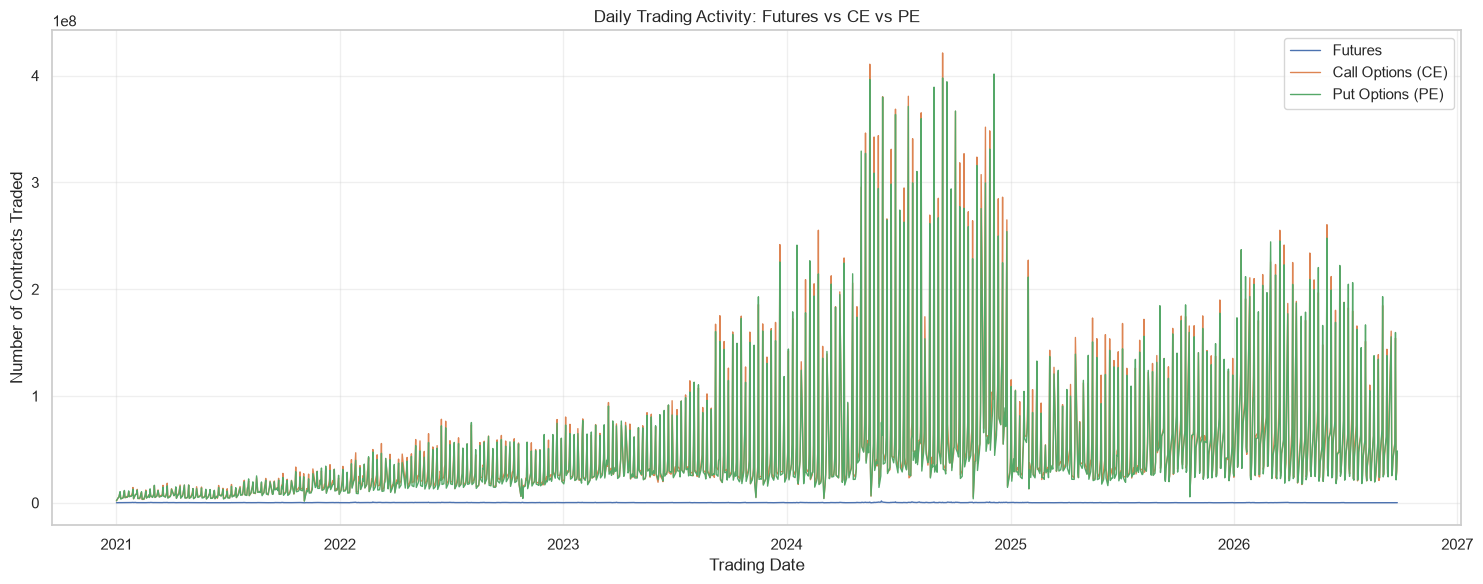

In [14]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_comparison["Date"],
    daily_comparison["Futures_Contracts"],
    label="Futures",
    linewidth=1
)

plt.plot(
    daily_comparison["Date"],
    daily_comparison["CE_Contracts"],
    label="Call Options (CE)",
    linewidth=1
)

plt.plot(
    daily_comparison["Date"],
    daily_comparison["PE_Contracts"],
    label="Put Options (PE)",
    linewidth=1
)

plt.title("Daily Trading Activity: Futures vs CE vs PE")
plt.xlabel("Trading Date")
plt.ylabel("Number of Contracts Traded")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
monthly_comparison = (
    daily_comparison
    .assign(Month=lambda x: x["Date"].dt.to_period("M"))
    .groupby("Month")[
        ["Futures_Contracts", "CE_Contracts", "PE_Contracts"]
    ]
    .sum()
    .reset_index()
)

monthly_comparison["Month"] = (
    monthly_comparison["Month"].dt.to_timestamp()
)

display(monthly_comparison.head())

,Month,Futures_Contracts,CE_Contracts,PE_Contracts
0,2021-01-01,"3,556,745.0000","133,053,871.0000","132,355,955.0000"
1,2021-02-01,"3,770,050.0000","141,962,259.0000","141,074,206.0000"
2,2021-03-01,"4,179,946.0000","178,559,787.0000","166,856,003.0000"
3,2021-04-01,"3,372,804.0000","170,697,158.0000","163,925,891.0000"
4,2021-05-01,"2,703,365.0000","155,599,489.0000","145,574,471.0000"


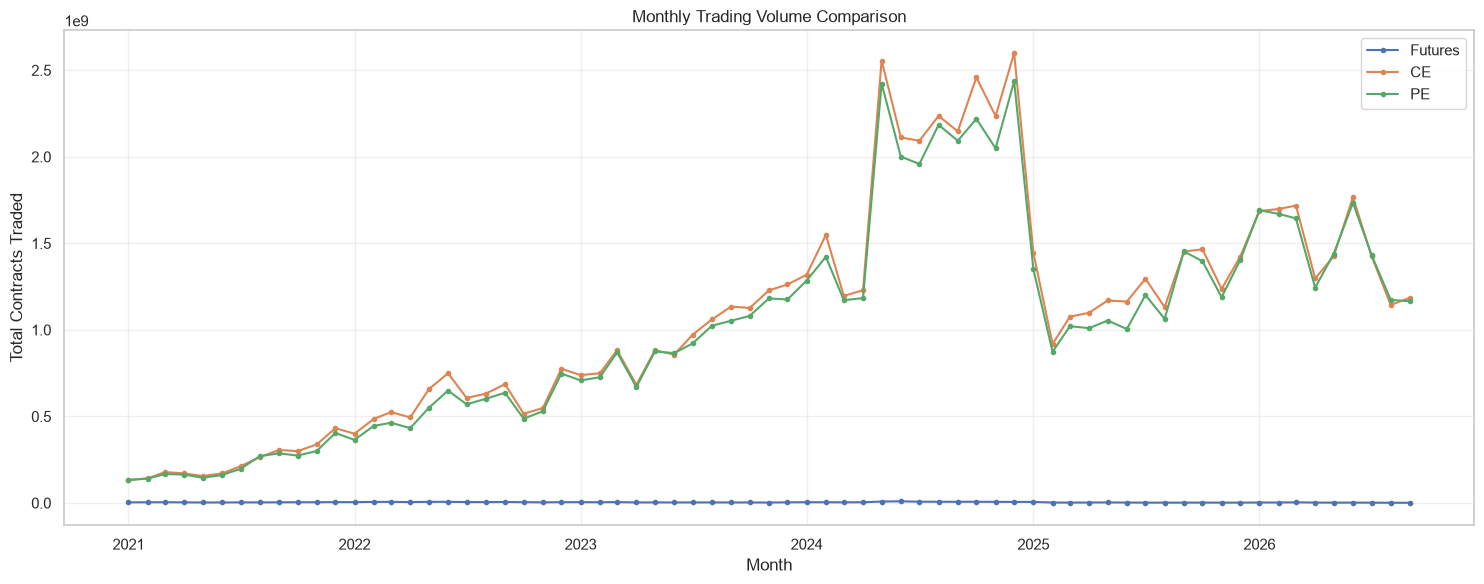

In [16]:
plt.figure(figsize=(15, 6))

plt.plot(
    monthly_comparison["Month"],
    monthly_comparison["Futures_Contracts"],
    label="Futures",
    marker="o",
    markersize=3
)

plt.plot(
    monthly_comparison["Month"],
    monthly_comparison["CE_Contracts"],
    label="CE",
    marker="o",
    markersize=3
)

plt.plot(
    monthly_comparison["Month"],
    monthly_comparison["PE_Contracts"],
    label="PE",
    marker="o",
    markersize=3
)

plt.title("Monthly Trading Volume Comparison")
plt.xlabel("Month")
plt.ylabel("Total Contracts Traded")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
yearly_comparison = (
    daily_comparison
    .assign(Year=lambda x: x["Date"].dt.year)
    .groupby("Year")[
        ["Futures_Contracts", "CE_Contracts", "PE_Contracts"]
    ]
    .sum()
    .reset_index()
)

display(yearly_comparison)

,Year,Futures_Contracts,CE_Contracts,PE_Contracts
0,2021,"43,398,575.0000","2,802,276,836.0000","2,643,790,376.0000"
1,2022,"62,889,450.0000","7,074,321,624.0000","6,476,836,815.0000"
2,2023,"40,039,536.0000","11,575,694,439.0000","11,150,975,594.0000"
3,2024,"73,882,452.0000","23,728,295,044.0000","22,425,262,937.0000"
4,2025,"29,854,788.0000","14,875,862,699.0000","14,021,322,760.0000"
5,2026,"18,713,836.0000","13,347,973,735.0000","13,195,184,340.0000"


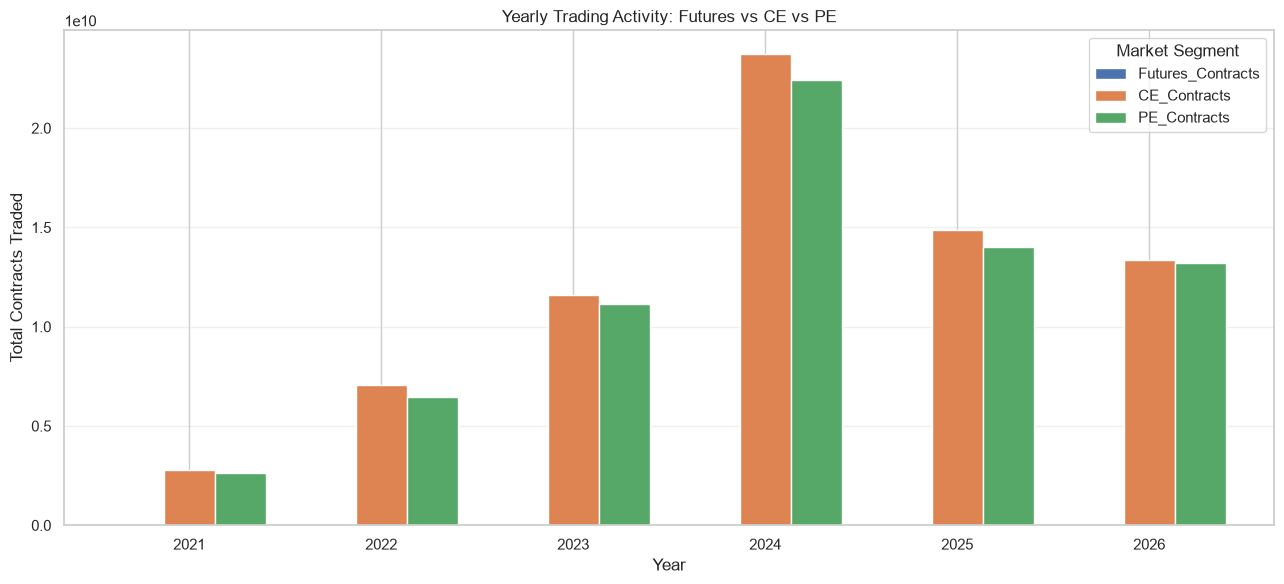

In [18]:
yearly_plot = yearly_comparison.set_index("Year")

yearly_plot.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Yearly Trading Activity: Futures vs CE vs PE")
plt.xlabel("Year")
plt.ylabel("Total Contracts Traded")
plt.xticks(rotation=0)
plt.legend(title="Market Segment")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
total_futures = daily_comparison["Futures_Contracts"].sum()
total_ce = daily_comparison["CE_Contracts"].sum()
total_pe = daily_comparison["PE_Contracts"].sum()

total_market_contracts = (
    total_futures + total_ce + total_pe
)

volume_contribution = pd.DataFrame({
    "Market Segment": ["Futures", "CE", "PE"],
    "Total Contracts": [
        total_futures,
        total_ce,
        total_pe
    ],
    "Contribution (%)": [
        total_futures / total_market_contracts * 100,
        total_ce / total_market_contracts * 100,
        total_pe / total_market_contracts * 100
    ]
})

display(volume_contribution.round(3))

,Market Segment,Total Contracts,Contribution (%)
0,Futures,"268,778,637.0000",0.1870
1,CE,"73,404,424,377.0000",51.1220
2,PE,"69,913,372,822.0000",48.6910


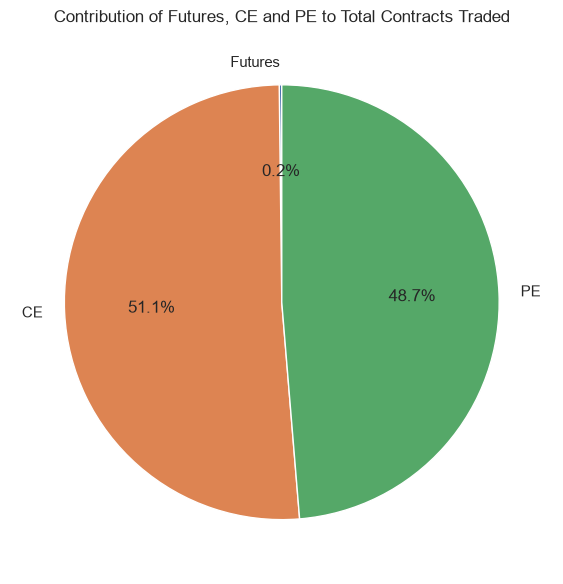

In [20]:
plt.figure(figsize=(8, 6))

plt.pie(
    volume_contribution["Total Contracts"],
    labels=volume_contribution["Market Segment"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Contribution of Futures, CE and PE to Total Contracts Traded")
plt.tight_layout()
plt.show()

In [21]:
average_daily_activity = pd.DataFrame({
    "Market Segment": ["Futures", "CE", "PE"],
    "Average Daily Contracts": [
        daily_comparison["Futures_Contracts"].mean(),
        daily_comparison["CE_Contracts"].mean(),
        daily_comparison["PE_Contracts"].mean()
    ],
    "Maximum Daily Contracts": [
        daily_comparison["Futures_Contracts"].max(),
        daily_comparison["CE_Contracts"].max(),
        daily_comparison["PE_Contracts"].max()
    ],
    "Minimum Daily Contracts": [
        daily_comparison["Futures_Contracts"].min(),
        daily_comparison["CE_Contracts"].min(),
        daily_comparison["PE_Contracts"].min()
    ]
})

display(average_daily_activity.round(2))

,Market Segment,Average Daily Contracts,Maximum Daily Contracts,Minimum Daily Contracts
0,Futures,"189,147.5300","1,746,793.0000","20,264.0000"
1,CE,"51,656,878.5200","421,147,400.0000","1,831,539.0000"
2,PE,"49,200,121.6200","401,452,352.0000","1,531,666.0000"


In [22]:
activity_columns = {
    "Futures": "Futures_Contracts",
    "CE": "CE_Contracts",
    "PE": "PE_Contracts"
}

highest_activity_dates = []

for segment, column in activity_columns.items():

    highest_row = daily_comparison.loc[
        daily_comparison[column].idxmax()
    ]

    highest_activity_dates.append({
        "Market Segment": segment,
        "Date": highest_row["Date"],
        "Contracts Traded": highest_row[column]
    })

highest_activity_df = pd.DataFrame(highest_activity_dates)

display(highest_activity_df)

,Market Segment,Date,Contracts Traded
0,Futures,2024-06-04,"1,746,793.0000"
1,CE,2024-09-12,"421,147,400.0000"
2,PE,2024-12-05,"401,452,352.0000"


### Section 3 - Key Observations

This section compared the trading activity of NIFTY 50 Futures,
Call Options, and Put Options.

Daily, monthly, and yearly trading volumes were examined to
understand changes in market activity over time.

The relative contribution of each segment and its average daily
trading activity were also calculated.

The results provide a comparative overview of trading activity
and will support further analysis of prices, returns, and
Open Interest in the following sections.

## 4. Comparative Price and Return Analysis

This section compares the price behaviour and daily returns of
NIFTY 50 Futures, Call Options (CE), and Put Options (PE).

The analysis focuses on:

- Daily average closing prices.
- Percentage returns.
- Return distributions.
- Volatility comparison.
- Identification of periods with significant price movements.

Since futures and options have different price structures,
percentage returns are used for comparative analysis.

Returns are calculated separately for each individual contract using consecutive closing prices. The resulting contract-level returns are then aggregated by trading date using their mean and median.

This approach avoids calculating percentage changes between average prices of different contracts. The daily aggregate returns represent the average performance of contracts observed on each date and do not represent the returns of a single fixed investment portfolio.

In [67]:
def calculate_contract_returns(df, contract_columns):
    """
    Calculate percentage returns within individual contracts,
    then summarize contract returns by trading date.
    """

    required = ["Date", "Close"] + contract_columns

    missing = [col for col in required if col not in df.columns]

    if missing:
        raise ValueError(f"Missing columns: {missing}")

    data = df[required].copy()

    data = data.dropna(subset=["Date", "Close"] + contract_columns)

    data = data.sort_values(contract_columns + ["Date"])

    data["Contract_Return"] = (
        data.groupby(contract_columns)["Close"]
        .pct_change(fill_method=None) * 100
    )

    data["Contract_Return"] = data["Contract_Return"].replace(
        [np.inf, -np.inf], np.nan
    )

    daily_summary = (
        data.groupby("Date")
        .agg(
            Mean_Return=("Contract_Return", "mean"),
            Median_Return=("Contract_Return", "median"),
            Contracts_Observed=("Contract_Return", "count")
        )
        .reset_index()
    )

    return daily_summary

In [68]:
# Identify contract-level grouping columns
futures_keys = [
    col for col in ["Symbol", "Expiry"]
    if col in futures_analysis.columns
]

option_keys = [
    col for col in ["Symbol", "Expiry", "Strike Price"]
    if col in calls_analysis.columns
]

print("Futures grouping columns:", futures_keys)
print("Options grouping columns:", option_keys)

assert futures_keys, "No futures contract identifiers found."
assert {"Expiry", "Strike Price"}.issubset(option_keys), (
    "Expiry and Strike Price are required for option contract returns."
)

# Calculate returns within individual contracts
futures_contract_daily = calculate_contract_returns(
    futures_analysis,
    futures_keys
)

ce_contract_daily = calculate_contract_returns(
    calls_analysis,
    option_keys
)

pe_contract_daily = calculate_contract_returns(
    puts_analysis,
    option_keys
)

# Create aligned daily return dataset
daily_returns = (
    futures_contract_daily[
        ["Date", "Mean_Return"]
    ]
    .rename(columns={"Mean_Return": "Futures_Return"})
    .merge(
        ce_contract_daily[["Date", "Mean_Return"]].rename(
            columns={"Mean_Return": "CE_Return"}
        ),
        on="Date",
        how="inner"
    )
    .merge(
        pe_contract_daily[["Date", "Mean_Return"]].rename(
            columns={"Mean_Return": "PE_Return"}
        ),
        on="Date",
        how="inner"
    )
    .sort_values("Date")
    .reset_index(drop=True)
)

display(daily_returns.head(10))
print("Aligned return observations:", len(daily_returns))

Futures grouping columns: ['Symbol', 'Expiry']
Options grouping columns: ['Symbol', 'Expiry', 'Strike Price']


,Date,Futures_Return,CE_Return,PE_Return
0,2021-01-01,NaN,NaN,NaN
1,2021-01-04,0.7773,4.3953,-8.0393
2,2021-01-05,0.3707,1.3733,-1.3253
3,2021-01-06,-0.1971,1.2933,-3.5717
4,2021-01-07,0.0254,-3.8481,-8.2553
5,2021-01-08,1.2316,5.5742,-8.6800
6,2021-01-11,0.8586,6.4436,-4.7370
7,2021-01-12,0.7284,4.8381,-4.6587
8,2021-01-13,0.0711,2.3472,-5.9717
9,2021-01-14,0.1412,-2.6264,-7.9954


Aligned return observations: 1421


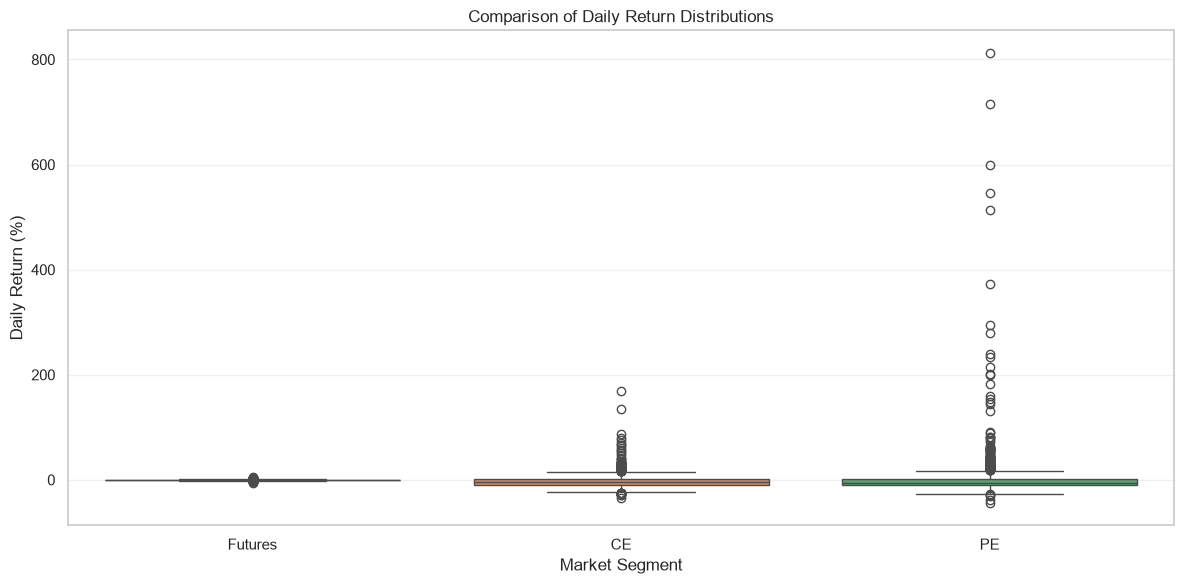

In [69]:
return_data = daily_returns[
    ["Futures_Return", "CE_Return", "PE_Return"]
].dropna()

plt.figure(figsize=(12, 6))

sns.boxplot(data=return_data)

plt.title("Comparison of Daily Return Distributions")
plt.xlabel("Market Segment")
plt.ylabel("Daily Return (%)")
plt.xticks(
    ticks=[0, 1, 2],
    labels=["Futures", "CE", "PE"]
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
return_summary = pd.DataFrame({
    "Futures": daily_returns["Futures_Return"].describe(),
    "CE": daily_returns["CE_Return"].describe(),
    "PE": daily_returns["PE_Return"].describe()
})

display(return_summary.round(4))

,Futures,CE,PE
count,"1,420.0000","1,420.0000","1,420.0000"
mean,0.0394,0.0864,0.1387
std,0.8939,3.3052,5.2670
min,-6.3236,-25.5545,-32.1538
25%,-0.4426,-1.5833,-2.4611
50%,0.0506,-0.0277,-0.1771
75%,0.5507,1.5403,2.2396
max,4.6864,20.0530,51.7990


In [28]:
volatility_comparison = pd.DataFrame({
    "Market Segment": ["Futures", "CE", "PE"],
    "Daily Volatility (%)": [
        daily_returns["Futures_Return"].std(),
        daily_returns["CE_Return"].std(),
        daily_returns["PE_Return"].std()
    ]
})

volatility_comparison["Annualized Volatility (%)"] = (
    volatility_comparison["Daily Volatility (%)"]
    * np.sqrt(252)
)

display(volatility_comparison.round(4))

,Market Segment,Daily Volatility (%),Annualized Volatility (%)
0,Futures,0.8939,14.1906
1,CE,3.3052,52.4684
2,PE,5.2670,83.6114


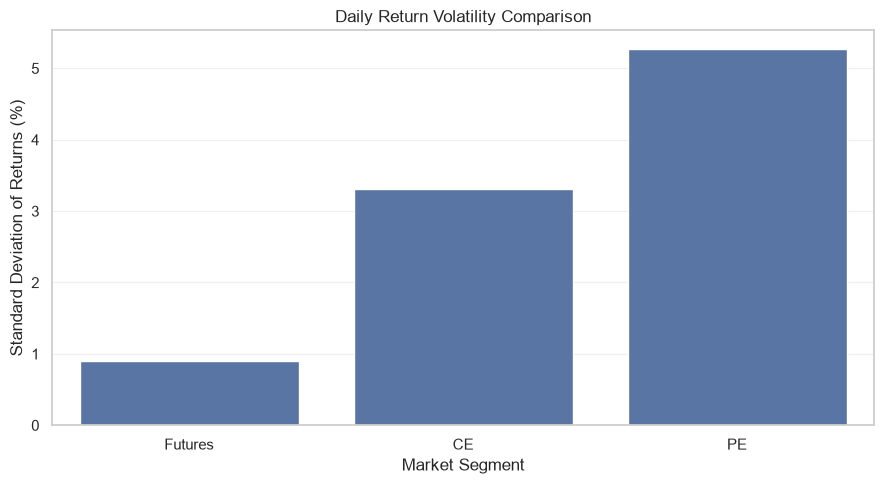

In [29]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=volatility_comparison,
    x="Market Segment",
    y="Daily Volatility (%)"
)

plt.title("Daily Return Volatility Comparison")
plt.xlabel("Market Segment")
plt.ylabel("Standard Deviation of Returns (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
return_correlation = daily_returns[
    ["Futures_Return", "CE_Return", "PE_Return"]
].corr()

display(return_correlation.round(4))

,Futures_Return,CE_Return,PE_Return
Futures_Return,1.0000,0.7152,-0.7270
CE_Return,0.7152,1.0000,-0.8015
PE_Return,-0.7270,-0.8015,1.0000


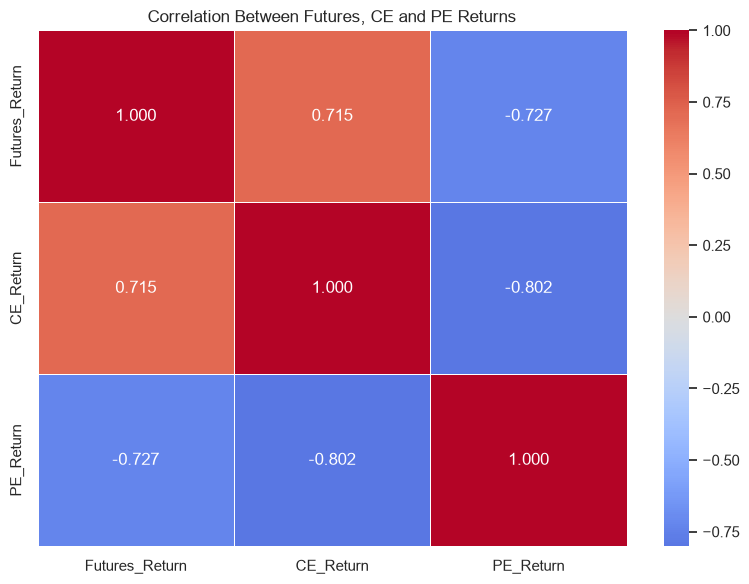

In [31]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    return_correlation,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".3f",
    linewidths=0.5
)

plt.title("Correlation Between Futures, CE and PE Returns")
plt.tight_layout()
plt.show()

In [32]:
extreme_movements = []

for column, segment in [
    ("Futures_Return", "Futures"),
    ("CE_Return", "CE"),
    ("PE_Return", "PE")
]:

    valid_returns = daily_returns.dropna(subset=[column])

    max_idx = valid_returns[column].idxmax()
    min_idx = valid_returns[column].idxmin()

    extreme_movements.append({
        "Market Segment": segment,
        "Largest Positive Return (%)": valid_returns.loc[max_idx, column],
        "Date of Largest Positive Return": valid_returns.loc[max_idx, "Date"],
        "Largest Negative Return (%)": valid_returns.loc[min_idx, column],
        "Date of Largest Negative Return": valid_returns.loc[min_idx, "Date"]
    })

extreme_movements_df = pd.DataFrame(extreme_movements)

display(extreme_movements_df.round(4))

,Market Segment,Largest Positive Return (%),Date of Largest Positive Return,Largest Negative Return (%),Date of Largest Negative Return
0,Futures,4.6864,2021-02-01,-6.3236,2024-06-04
1,CE,20.0530,2025-05-12,-25.5545,2024-06-04
2,PE,51.7990,2024-06-04,-32.1538,2025-05-12


### Section 4 - Key Observations

This section compares the daily returns of Futures, Call Options (CE), and Put Options (PE).

Returns are calculated separately for individual contracts using consecutive closing prices. The resulting contract-level returns are then aggregated by trading date using their mean and median.

This approach avoids calculating percentage changes between average prices of different contracts. The daily aggregate returns represent the average performance of contracts observed on each date and should not be interpreted as returns from a single fixed investment portfolio.

The analysis examines return distributions, volatility, correlations, and extreme daily movements. Further analysis of Open Interest and Put-Call Ratio will help investigate market positioning.

## 5. CE vs PE Open Interest Comparison

This section compares the Open Interest (OI) of NIFTY 50 Call Options
and Put Options.

The analysis focuses on:

- Daily aggregate CE and PE Open Interest.
- Changes in Open Interest over time.
- Relative Open Interest distribution.
- CE and PE Open Interest comparison.
- Identification of dates with significant Open Interest.

The objective is to understand how outstanding positions are
distributed between call and put options.

In [33]:
# Extract daily CE and PE Open Interest from aligned dataset
oi_comparison = daily_comparison[
    ["Date", "CE_OI", "PE_OI"]
].copy()

oi_comparison = oi_comparison.sort_values("Date").reset_index(drop=True)

display(oi_comparison.head())

,Date,CE_OI,PE_OI
0,2021-01-01,"46,307,550.0000","63,556,725.0000"
1,2021-01-04,"49,468,500.0000","75,260,775.0000"
2,2021-01-05,"54,993,150.0000","89,125,200.0000"
3,2021-01-06,"68,451,750.0000","85,296,075.0000"
4,2021-01-07,"78,445,575.0000","93,355,950.0000"


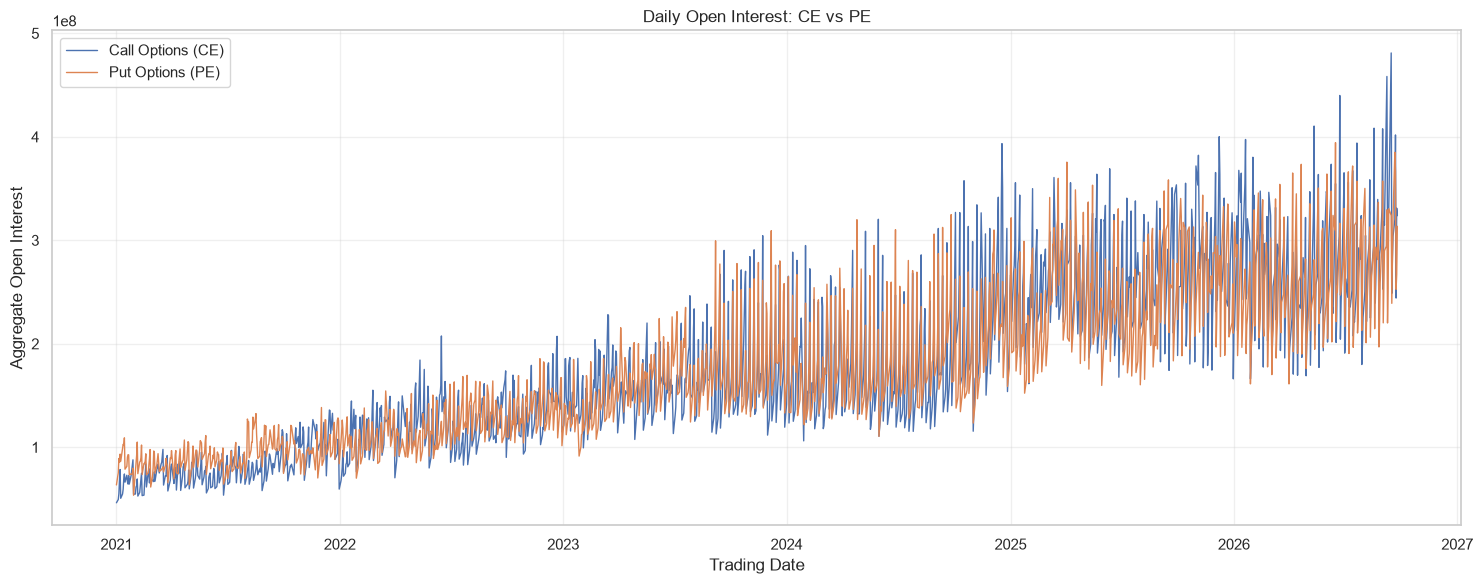

In [34]:
plt.figure(figsize=(15, 6))

plt.plot(
    oi_comparison["Date"],
    oi_comparison["CE_OI"],
    label="Call Options (CE)",
    linewidth=1
)

plt.plot(
    oi_comparison["Date"],
    oi_comparison["PE_OI"],
    label="Put Options (PE)",
    linewidth=1
)

plt.title("Daily Open Interest: CE vs PE")
plt.xlabel("Trading Date")
plt.ylabel("Aggregate Open Interest")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
oi_comparison["CE_OI_Change"] = oi_comparison["CE_OI"].diff()
oi_comparison["PE_OI_Change"] = oi_comparison["PE_OI"].diff()

display(oi_comparison.head(10))

,Date,CE_OI,PE_OI,CE_OI_Change,PE_OI_Change
0,2021-01-01,"46,307,550.0000","63,556,725.0000",NaN,NaN
1,2021-01-04,"49,468,500.0000","75,260,775.0000","3,160,950.0000","11,704,050.0000"
2,2021-01-05,"54,993,150.0000","89,125,200.0000","5,524,650.0000","13,864,425.0000"
3,2021-01-06,"68,451,750.0000","85,296,075.0000","13,458,600.0000","-3,829,125.0000"
4,2021-01-07,"78,445,575.0000","93,355,950.0000","9,993,825.0000","8,059,875.0000"
5,2021-01-08,"50,645,250.0000","86,461,425.0000","-27,800,325.0000","-6,894,525.0000"
6,2021-01-11,"54,822,225.0000","98,498,775.0000","4,176,975.0000","12,037,350.0000"
7,2021-01-12,"59,430,825.0000","102,796,275.0000","4,608,600.0000","4,297,500.0000"
8,2021-01-13,"69,550,050.0000","101,875,875.0000","10,119,225.0000","-920,400.0000"
9,2021-01-14,"74,121,375.0000","109,054,350.0000","4,571,325.0000","7,178,475.0000"


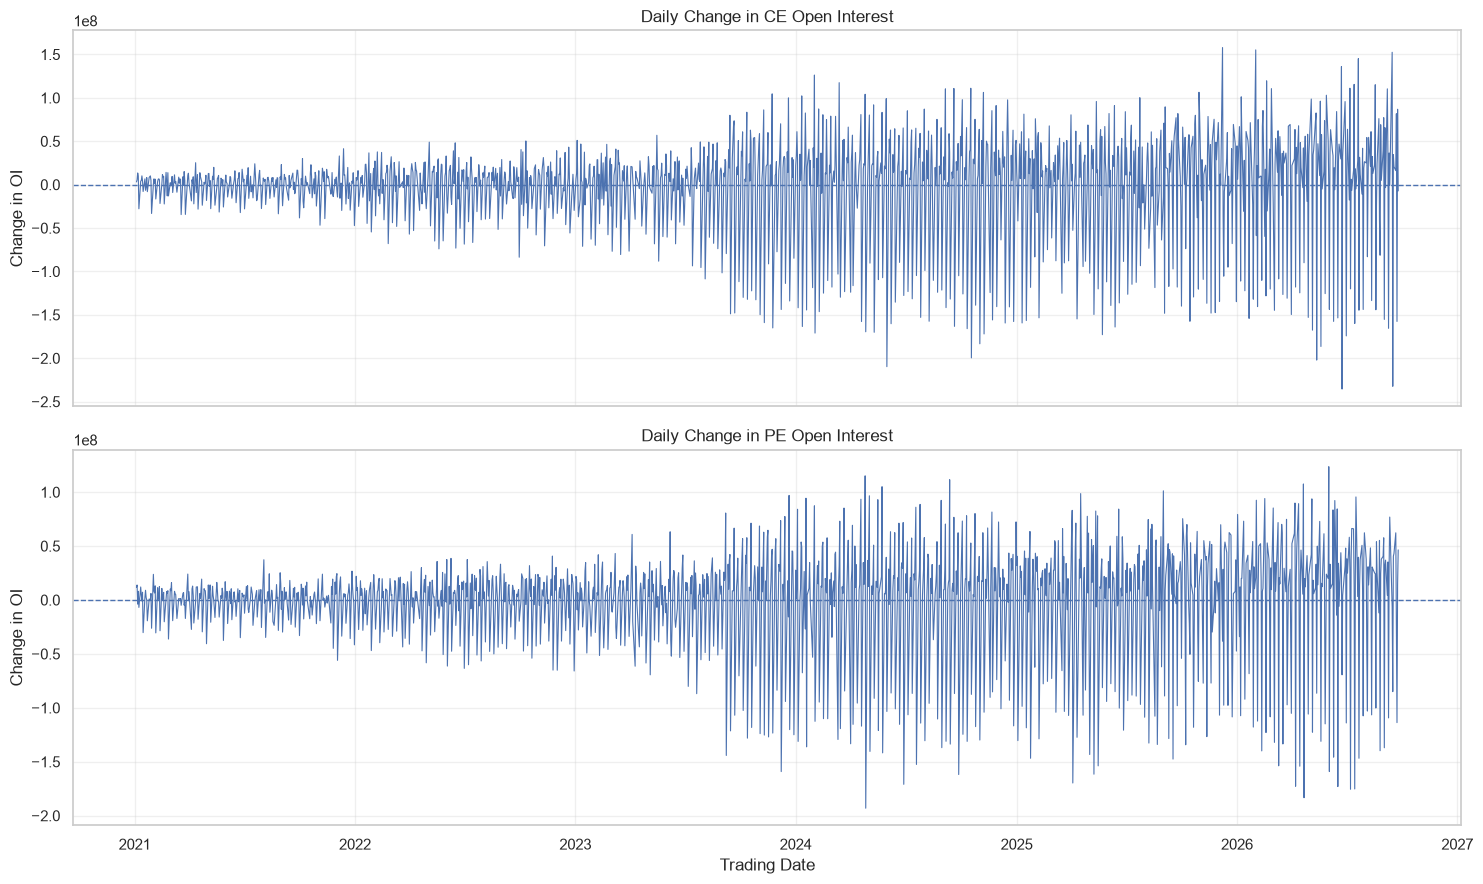

In [36]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

axes[0].plot(
    oi_comparison["Date"],
    oi_comparison["CE_OI_Change"],
    linewidth=0.8
)

axes[0].axhline(0, linestyle="--", linewidth=1)
axes[0].set_title("Daily Change in CE Open Interest")
axes[0].set_ylabel("Change in OI")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    oi_comparison["Date"],
    oi_comparison["PE_OI_Change"],
    linewidth=0.8
)

axes[1].axhline(0, linestyle="--", linewidth=1)
axes[1].set_title("Daily Change in PE Open Interest")
axes[1].set_xlabel("Trading Date")
axes[1].set_ylabel("Change in OI")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [37]:
total_ce_oi = oi_comparison["CE_OI"].sum()
total_pe_oi = oi_comparison["PE_OI"].sum()

total_oi = total_ce_oi + total_pe_oi

oi_contribution = pd.DataFrame({
    "Market Segment": ["CE", "PE"],
    "Total Daily OI Observations": [
        total_ce_oi,
        total_pe_oi
    ],
    "Contribution (%)": [
        total_ce_oi / total_oi * 100 if total_oi else np.nan,
        total_pe_oi / total_oi * 100 if total_oi else np.nan
    ]
})

display(oi_contribution.round(3))

,Market Segment,Total Daily OI Observations,Contribution (%)
0,CE,"257,849,669,235.0000",50.4950
1,PE,"252,795,790,030.0000",49.5050


In [38]:
average_oi_comparison = pd.DataFrame({
    "Market Segment": ["CE", "PE"],
    "Average Daily OI": [
        oi_comparison["CE_OI"].mean(),
        oi_comparison["PE_OI"].mean()
    ],
    "Maximum Daily OI": [
        oi_comparison["CE_OI"].max(),
        oi_comparison["PE_OI"].max()
    ],
    "Minimum Daily OI": [
        oi_comparison["CE_OI"].min(),
        oi_comparison["PE_OI"].min()
    ]
})

display(average_oi_comparison.round(2))

,Market Segment,Average Daily OI,Maximum Daily OI,Minimum Daily OI
0,CE,"181,456,487.8500","480,998,980.0000","46,307,550.0000"
1,PE,"177,899,922.6100","394,354,090.0000","53,572,275.0000"


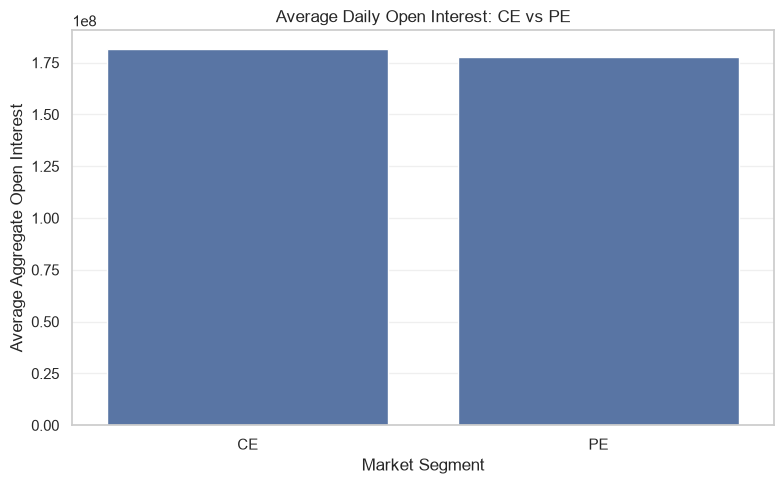

In [39]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=average_oi_comparison,
    x="Market Segment",
    y="Average Daily OI"
)

plt.title("Average Daily Open Interest: CE vs PE")
plt.xlabel("Market Segment")
plt.ylabel("Average Aggregate Open Interest")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
oi_correlation = oi_comparison[
    ["CE_OI", "PE_OI"]
].corr()

display(oi_correlation.round(4))

,CE_OI,PE_OI
CE_OI,1.0000,0.8802
PE_OI,0.8802,1.0000


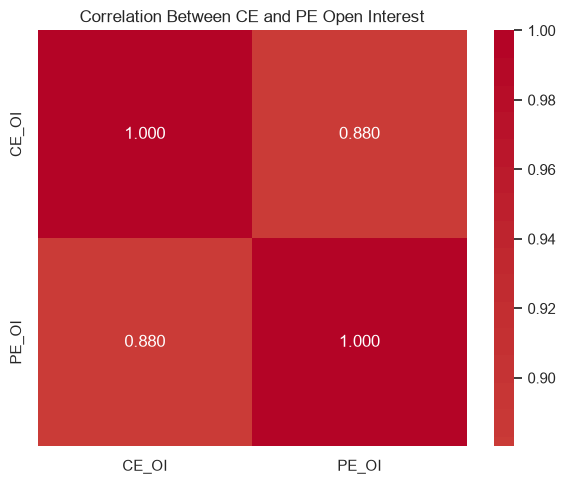

In [41]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    oi_correlation,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".3f"
)

plt.title("Correlation Between CE and PE Open Interest")
plt.tight_layout()
plt.show()

In [42]:
ce_max_date = oi_comparison.loc[
    oi_comparison["CE_OI"].idxmax()
]

pe_max_date = oi_comparison.loc[
    oi_comparison["PE_OI"].idxmax()
]

oi_peak_summary = pd.DataFrame({
    "Market Segment": ["CE", "PE"],
    "Maximum Open Interest": [
        ce_max_date["CE_OI"],
        pe_max_date["PE_OI"]
    ],
    "Date": [
        ce_max_date["Date"],
        pe_max_date["Date"]
    ]
})

display(oi_peak_summary)

,Market Segment,Maximum Open Interest,Date
0,CE,"480,998,980.0000",2026-09-15
1,PE,"394,354,090.0000",2026-06-16


### Section 5 - Key Observations

This section compared the daily aggregate Open Interest of
NIFTY 50 Call Options and Put Options.

The analysis examined daily OI trends, changes in OI,
average daily OI, maximum OI, and the correlation between
CE and PE Open Interest.

These results provide insights into the distribution and
movement of outstanding option positions over the study period.

The analysis is descriptive and does not independently
establish market direction or investor sentiment.

## 6. Put-Call Ratio (PCR) Analysis

The Put-Call Ratio (PCR) is used to compare Put Option Open Interest
with Call Option Open Interest.

This section examines:

- Daily Open Interest PCR.
- PCR trends over time.
- Distribution of PCR values.
- Summary statistics.
- Identification of unusually high and low PCR observations.

The PCR is calculated using aggregate daily Open Interest.
It is treated as a descriptive market indicator rather than
a standalone predictor of market direction.

In [43]:
pcr_daily = oi_comparison[["Date", "CE_OI", "PE_OI"]].copy()

pcr_daily["PCR"] = np.where(
    pcr_daily["CE_OI"] > 0,
    pcr_daily["PE_OI"] / pcr_daily["CE_OI"],
    np.nan
)

display(pcr_daily.head(10))

,Date,CE_OI,PE_OI,PCR
0,2021-01-01,"46,307,550.0000","63,556,725.0000",1.3725
1,2021-01-04,"49,468,500.0000","75,260,775.0000",1.5214
2,2021-01-05,"54,993,150.0000","89,125,200.0000",1.6207
3,2021-01-06,"68,451,750.0000","85,296,075.0000",1.2461
4,2021-01-07,"78,445,575.0000","93,355,950.0000",1.1901
5,2021-01-08,"50,645,250.0000","86,461,425.0000",1.7072
6,2021-01-11,"54,822,225.0000","98,498,775.0000",1.7967
7,2021-01-12,"59,430,825.0000","102,796,275.0000",1.7297
8,2021-01-13,"69,550,050.0000","101,875,875.0000",1.4648
9,2021-01-14,"74,121,375.0000","109,054,350.0000",1.4713


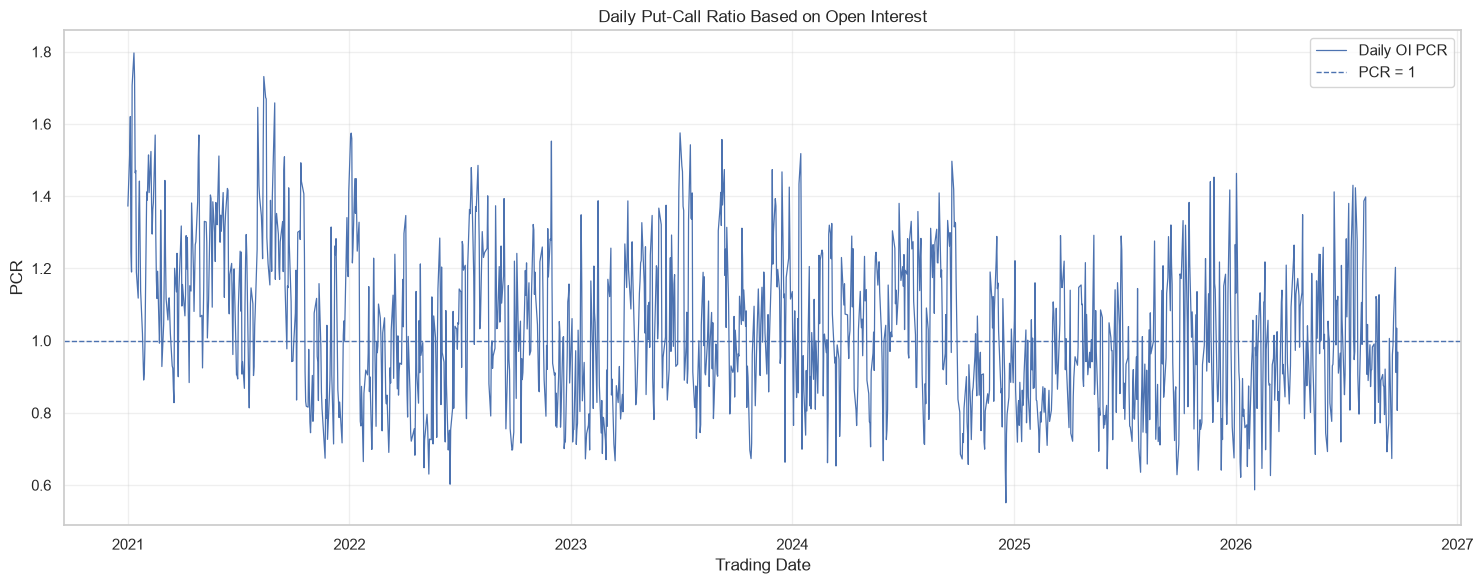

In [44]:
plt.figure(figsize=(15, 6))

plt.plot(
    pcr_daily["Date"],
    pcr_daily["PCR"],
    linewidth=0.9,
    label="Daily OI PCR"
)

plt.axhline(
    1,
    linestyle="--",
    linewidth=1,
    label="PCR = 1"
)

plt.title("Daily Put-Call Ratio Based on Open Interest")
plt.xlabel("Trading Date")
plt.ylabel("PCR")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

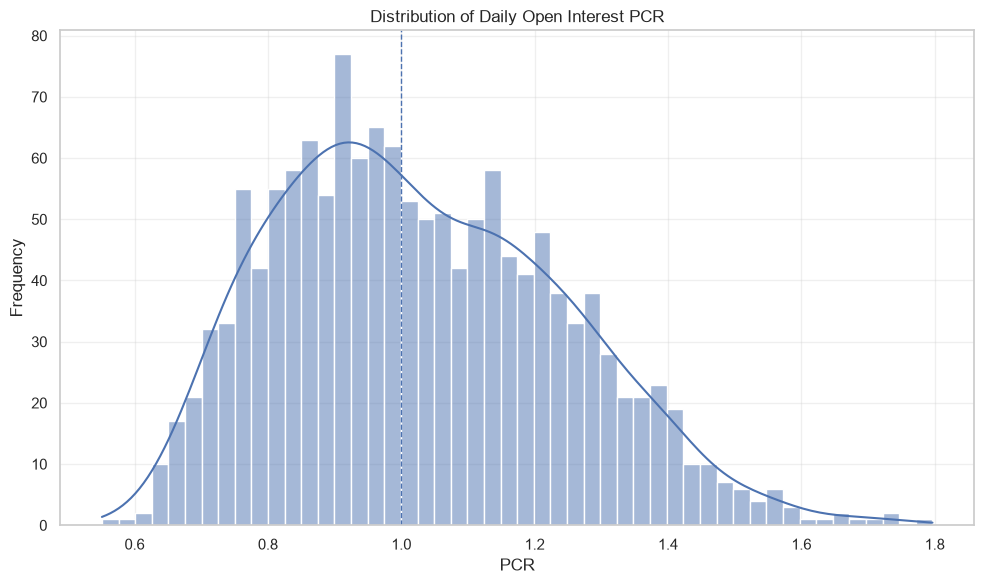

In [45]:
plt.figure(figsize=(10, 6))

sns.histplot(
    pcr_daily["PCR"].dropna(),
    bins=50,
    kde=True
)

plt.axvline(1, linestyle="--", linewidth=1)

plt.title("Distribution of Daily Open Interest PCR")
plt.xlabel("PCR")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [46]:
pcr_summary = pcr_daily["PCR"].describe().to_frame(
    name="PCR Value"
)

display(pcr_summary.round(4))

print("Median PCR:", pcr_daily["PCR"].median())
print("Mean PCR:", pcr_daily["PCR"].mean())

,PCR Value
count,"1,421.0000"
mean,1.0278
std,0.2148
min,0.5511
25%,0.8625
50%,1.0013
75%,1.1785
max,1.7967


Median PCR: 1.0013001110816784
Mean PCR: 1.0278142970210407


In [47]:
valid_pcr = pcr_daily.dropna(subset=["PCR"])

highest_pcr = valid_pcr.loc[valid_pcr["PCR"].idxmax()]
lowest_pcr = valid_pcr.loc[valid_pcr["PCR"].idxmin()]

pcr_extremes = pd.DataFrame([
    {
        "Observation": "Highest PCR",
        "Date": highest_pcr["Date"],
        "PCR": highest_pcr["PCR"]
    },
    {
        "Observation": "Lowest PCR",
        "Date": lowest_pcr["Date"],
        "PCR": lowest_pcr["PCR"]
    }
])

display(pcr_extremes.round(4))

,Observation,Date,PCR
0,Highest PCR,2021-01-11,1.7967
1,Lowest PCR,2024-12-18,0.5511


### Section 6 — Key Observations

The daily Open Interest PCR was calculated by dividing aggregate
Put Open Interest by aggregate Call Open Interest.

A PCR above 1 indicates that aggregate Put Open Interest exceeds
aggregate Call Open Interest, while a PCR below 1 indicates the
opposite.

The time-series visualization and descriptive statistics help
identify changes and variations in the relationship between
Put and Call Open Interest.

PCR should not be interpreted as a definitive indicator of
future market direction.

## 7. Correlation Analysis

This section investigates statistical relationships between
different NIFTY 50 derivatives market variables.

The analysis examines:

- Trading volume relationships.
- Open Interest relationships.
- Relationships between futures, CE, and PE returns.
- Pearson correlation.
- Spearman rank correlation.

The objective is to identify variables that exhibit positive,
negative, or weak statistical associations.

In [48]:
correlation_data = daily_comparison.merge(
    daily_returns,
    on="Date",
    how="inner"
)

correlation_data = correlation_data.merge(
    pcr_daily[["Date", "PCR"]],
    on="Date",
    how="left"
)

# Calculate daily changes in aggregate Open Interest
for column in ["Futures_OI", "CE_OI", "PE_OI"]:
    correlation_data[f"{column}_Change"] = (
        correlation_data[column].diff()
    )

print("Correlation dataset shape:", correlation_data.shape)

display(correlation_data.head())

Correlation dataset shape: (1421, 17)


,Date,Futures_Contracts,Futures_OI,Futures_Records,CE_Contracts,CE_OI,CE_Records,PE_Contracts,PE_OI,PE_Records,Futures_Return,CE_Return,PE_Return,PCR,Futures_OI_Change,CE_OI_Change,PE_OI_Change
0,2021-01-01,"64,130.0000","13,154,850.0000",3,"1,831,539.0000","46,307,550.0000",986,"1,980,273.0000","63,556,725.0000",1069,NaN,NaN,NaN,1.3725,NaN,NaN,NaN
1,2021-01-04,"139,548.0000","13,716,075.0000",3,"4,654,570.0000","49,468,500.0000",986,"4,866,202.0000","75,260,775.0000",1069,0.7772,3.0941,-4.1395,1.5214,"561,225.0000","3,160,950.0000","11,704,050.0000"
2,2021-01-05,"135,453.0000","14,254,725.0000",3,"5,324,933.0000","54,993,150.0000",1016,"5,120,351.0000","89,125,200.0000",1099,0.3707,-1.9070,1.4270,1.6207,"538,650.0000","5,524,650.0000","13,864,425.0000"
3,2021-01-06,"162,142.0000","13,431,900.0000",3,"7,547,789.0000","68,451,750.0000",1026,"8,145,315.0000","85,296,075.0000",1109,-0.1971,0.4870,-0.0083,1.2461,"-822,825.0000","13,458,600.0000","-3,829,125.0000"
4,2021-01-07,"103,900.0000","13,371,150.0000",3,"9,764,517.0000","78,445,575.0000",1026,"10,427,242.0000","93,355,950.0000",1109,0.0254,0.7146,-1.1989,1.1901,"-60,750.0000","9,993,825.0000","8,059,875.0000"


In [49]:
correlation_columns = [
    "Futures_Contracts",
    "CE_Contracts",
    "PE_Contracts",
    "Futures_OI",
    "CE_OI",
    "PE_OI",
    "Futures_Return",
    "CE_Return",
    "PE_Return",
    "PCR"
]

correlation_matrix_data = correlation_data[
    correlation_columns
].replace([np.inf, -np.inf], np.nan)

display(correlation_matrix_data.describe().round(3))

,Futures_Contracts,CE_Contracts,PE_Contracts,Futures_OI,CE_OI,PE_OI,Futures_Return,CE_Return,PE_Return,PCR
count,"1,421.0000","1,421.0000","1,421.0000","1,421.0000","1,421.0000","1,421.0000","1,420.0000","1,420.0000","1,420.0000","1,421.0000"
mean,"189,147.5280","51,656,878.5200","49,200,121.6200","14,935,065.3480","181,456,487.8500","177,899,922.6110",0.0390,0.0860,0.1390,1.0280
std,"121,209.2910","61,603,625.4890","59,760,497.1900","3,141,113.2550","81,959,109.1070","71,508,185.0160",0.8940,3.3050,5.2670,0.2150
min,"20,264.0000","1,831,539.0000","1,531,666.0000","9,641,650.0000","46,307,550.0000","53,572,275.0000",-6.3240,-25.5540,-32.1540,0.5510
25%,"109,008.0000","20,761,809.0000","18,973,371.0000","12,545,500.0000","118,375,075.0000","118,623,400.0000",-0.4430,-1.5830,-2.4610,0.8620
50%,"162,909.0000","30,248,231.0000","28,327,207.0000","14,122,300.0000","162,897,275.0000","164,821,225.0000",0.0510,-0.0280,-0.1770,1.0010
75%,"237,843.0000","55,496,297.0000","52,627,996.0000","17,063,450.0000","242,117,100.0000","227,982,775.0000",0.5510,1.5400,2.2400,1.1790
max,"1,746,793.0000","421,147,400.0000","401,452,352.0000","29,861,975.0000","480,998,980.0000","394,354,090.0000",4.6860,20.0530,51.7990,1.7970


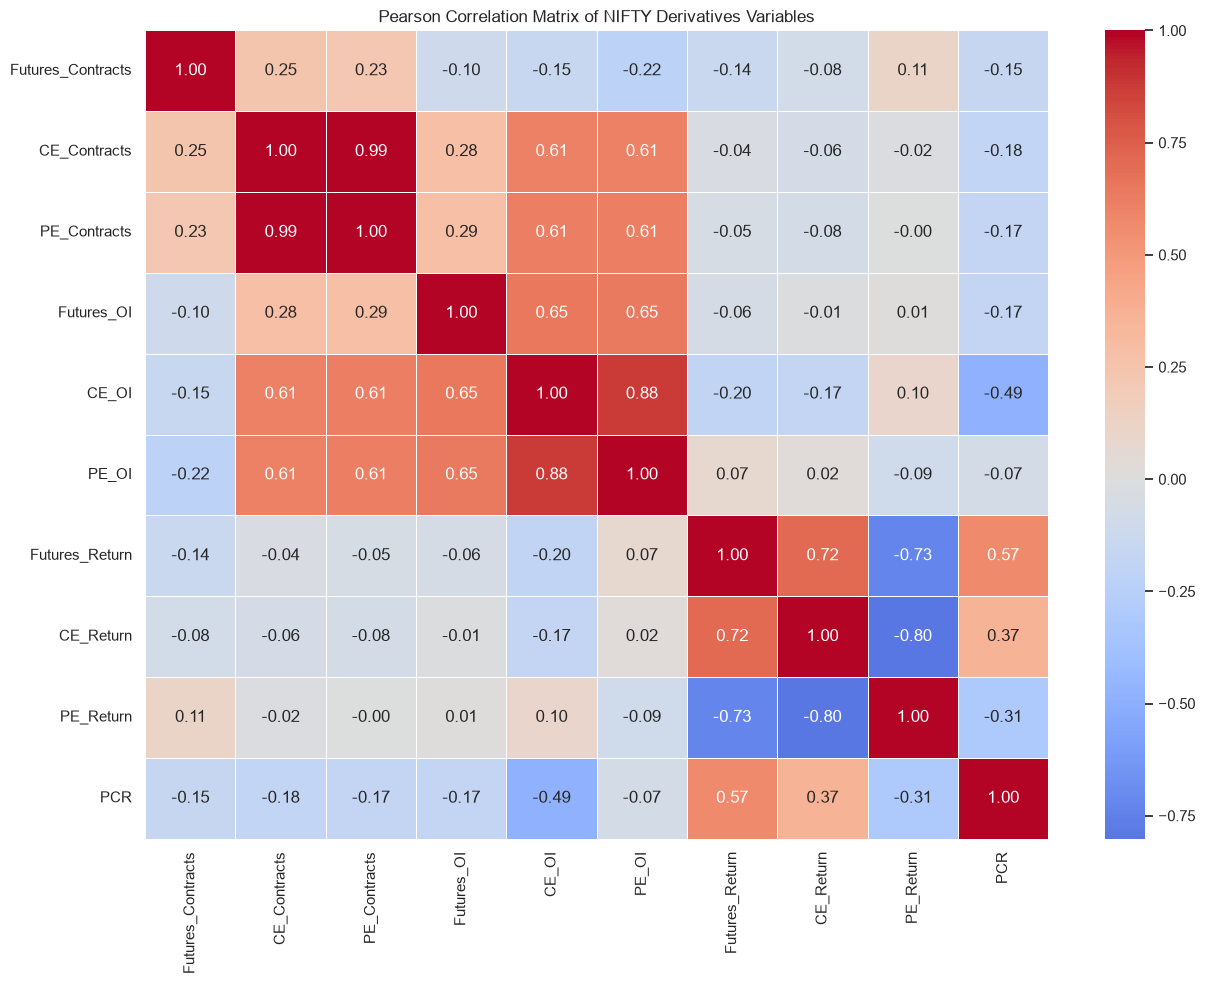

In [50]:
pearson_correlation = correlation_matrix_data.corr(
    method="pearson"
)

plt.figure(figsize=(13, 10))

sns.heatmap(
    pearson_correlation,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.4
)

plt.title("Pearson Correlation Matrix of NIFTY Derivatives Variables")
plt.tight_layout()
plt.show()

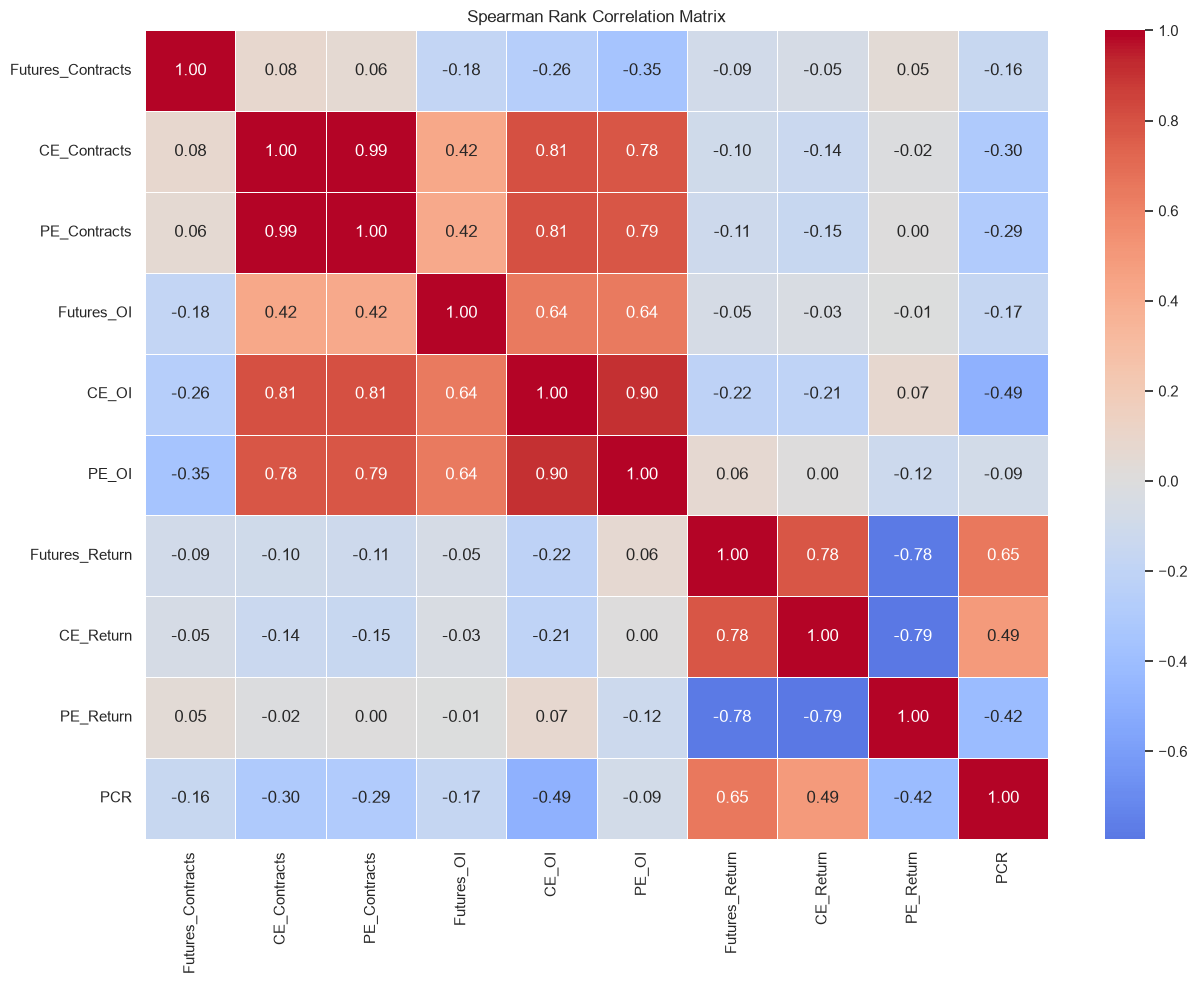

In [51]:
spearman_correlation = correlation_matrix_data.corr(
    method="spearman"
)

plt.figure(figsize=(13, 10))

sns.heatmap(
    spearman_correlation,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.4
)

plt.title("Spearman Rank Correlation Matrix")
plt.tight_layout()
plt.show()

In [52]:
selected_pairs = [
    ("Futures_Return", "CE_Return"),
    ("Futures_Return", "PE_Return"),
    ("CE_Return", "PE_Return"),
    ("CE_OI", "PE_OI"),
    ("CE_Contracts", "PE_Contracts"),
    ("Futures_Contracts", "CE_Contracts"),
    ("Futures_Contracts", "PE_Contracts")
]

selected_correlations = []

for variable_1, variable_2 in selected_pairs:

    pair_data = correlation_matrix_data[
        [variable_1, variable_2]
    ].dropna()

    pearson_value = pair_data[variable_1].corr(
        pair_data[variable_2],
        method="pearson"
    )

    spearman_value = pair_data[variable_1].corr(
        pair_data[variable_2],
        method="spearman"
    )

    selected_correlations.append({
        "Variable 1": variable_1,
        "Variable 2": variable_2,
        "Pearson Correlation": pearson_value,
        "Spearman Correlation": spearman_value,
        "Observations": len(pair_data)
    })

selected_correlation_df = pd.DataFrame(
    selected_correlations
)

display(selected_correlation_df.round(4))

,Variable 1,Variable 2,Pearson Correlation,Spearman Correlation,Observations
0,Futures_Return,CE_Return,0.7152,0.7788,1420
1,Futures_Return,PE_Return,-0.7270,-0.7828,1420
2,CE_Return,PE_Return,-0.8015,-0.7942,1420
3,CE_OI,PE_OI,0.8802,0.9048,1421
4,CE_Contracts,PE_Contracts,0.9947,0.9906,1421
5,Futures_Contracts,CE_Contracts,0.2453,0.0826,1421
6,Futures_Contracts,PE_Contracts,0.2307,0.0568,1421


### Section 7 - Key Observations

Pearson and Spearman correlation analyses were performed to
investigate relationships between trading activity, Open Interest,
PCR, and daily returns.

Pearson correlation measures linear association, whereas
Spearman correlation measures rank-based monotonic association.

Correlation does not establish causation. Relationships involving
daily average option premiums may also be affected by changes in
the available strike prices and expiry dates.

## 8. Statistical Hypothesis Testing

This section applies statistical hypothesis tests to investigate
differences and relationships in NIFTY 50 derivatives market data.

The analysis includes:

- Paired t-test for CE and PE daily aggregate returns.
- Wilcoxon signed-rank test for CE and PE Open Interest.
- Levene's test for equality of return variances.
- Pearson correlation significance tests.

The significance level is set to 5%.

The tests are applied to aligned daily observations. Their
interpretation considers the limitations of aggregate option
premium and Open Interest measures.

In [53]:
ALPHA = 0.05

print("Significance Level:", ALPHA)

Significance Level: 0.05


In [54]:
ce_pe_returns = daily_returns[
    ["CE_Return", "PE_Return"]
].dropna()

paired_t_result = stats.ttest_rel(
    ce_pe_returns["CE_Return"],
    ce_pe_returns["PE_Return"]
)

paired_t_summary = pd.DataFrame({
    "Metric": [
        "CE Mean Return (%)",
        "PE Mean Return (%)",
        "T-statistic",
        "P-value"
    ],
    "Value": [
        ce_pe_returns["CE_Return"].mean(),
        ce_pe_returns["PE_Return"].mean(),
        paired_t_result.statistic,
        paired_t_result.pvalue
    ]
})

display(paired_t_summary.round(6))

if paired_t_result.pvalue < ALPHA:
    print("Reject H0: Evidence of a difference in mean aggregate returns.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference in mean aggregate returns.")

,Metric,Value
0,CE Mean Return (%),0.0864
1,PE Mean Return (%),0.1387
2,T-statistic,-0.2417
3,P-value,0.8090


Fail to reject H0: Insufficient evidence of a difference in mean aggregate returns.


In [55]:
oi_test_data = oi_comparison[
    ["CE_OI", "PE_OI"]
].dropna()

oi_differences = (
    oi_test_data["CE_OI"] - oi_test_data["PE_OI"]
)

# Remove zero differences for the Wilcoxon test
nonzero_differences = oi_differences[oi_differences != 0]

if len(nonzero_differences) > 0:

    wilcoxon_result = stats.wilcoxon(
        nonzero_differences,
        alternative="two-sided"
    )

    print("Wilcoxon Statistic:", wilcoxon_result.statistic)
    print("P-value:", wilcoxon_result.pvalue)

    if wilcoxon_result.pvalue < ALPHA:
        print("Reject H0: Evidence of a systematic difference in paired CE and PE OI.")
    else:
        print("Fail to reject H0: Insufficient evidence of a systematic difference.")

else:
    print("Wilcoxon test not applicable: all paired differences are zero.")

Wilcoxon Statistic: 479957.0
P-value: 0.10323658704318012
Fail to reject H0: Insufficient evidence of a systematic difference.


In [56]:
futures_test_returns = daily_returns["Futures_Return"].dropna()
ce_test_returns = daily_returns["CE_Return"].dropna()
pe_test_returns = daily_returns["PE_Return"].dropna()

levene_result = stats.levene(
    futures_test_returns,
    ce_test_returns,
    pe_test_returns,
    center="median"
)

print("Levene Statistic:", levene_result.statistic)
print("P-value:", levene_result.pvalue)

if levene_result.pvalue < ALPHA:
    print("Reject H0: Evidence that at least one return variance differs.")
else:
    print("Fail to reject H0: Insufficient evidence of different variances.")

Levene Statistic: 391.42535323445003
P-value: 8.935218732493992e-157
Reject H0: Evidence that at least one return variance differs.


In [57]:
correlation_pairs = [
    ("Futures_Return", "CE_Return"),
    ("Futures_Return", "PE_Return"),
    ("CE_Return", "PE_Return")
]

correlation_test_results = []

for col1, col2 in correlation_pairs:

    pair = daily_returns[[col1, col2]].dropna()

    result = stats.pearsonr(
        pair[col1],
        pair[col2]
    )

    correlation_test_results.append({
        "Variable 1": col1,
        "Variable 2": col2,
        "Pearson r": result.statistic,
        "P-value": result.pvalue,
        "Observations": len(pair)
    })

correlation_test_df = pd.DataFrame(
    correlation_test_results
)

display(correlation_test_df.round(6))

,Variable 1,Variable 2,Pearson r,P-value,Observations
0,Futures_Return,CE_Return,0.7152,0.0000,1420
1,Futures_Return,PE_Return,-0.7270,0.0000,1420
2,CE_Return,PE_Return,-0.8015,0.0000,1420


In [58]:
number_of_tests = len(correlation_test_df)

correlation_test_df["Adjusted P-value"] = (
    correlation_test_df["P-value"] * number_of_tests
).clip(upper=1)

correlation_test_df["Significant After Correction"] = (
    correlation_test_df["Adjusted P-value"] < ALPHA
)

display(correlation_test_df.round(6))

,Variable 1,Variable 2,Pearson r,P-value,Observations,Adjusted P-value,Significant After Correction
0,Futures_Return,CE_Return,0.7152,0.0000,1420,0.0000,True
1,Futures_Return,PE_Return,-0.7270,0.0000,1420,0.0000,True
2,CE_Return,PE_Return,-0.8015,0.0000,1420,0.0000,True


In [59]:
hypothesis_test_summary = pd.DataFrame([
    {
        "Test": "Paired t-test: CE vs PE returns",
        "Statistic": paired_t_result.statistic,
        "P-value": paired_t_result.pvalue,
        "Decision": (
            "Reject H0"
            if paired_t_result.pvalue < ALPHA
            else "Fail to reject H0"
        )
    },
    {
        "Test": "Wilcoxon: CE vs PE Open Interest",
        "Statistic": (
            wilcoxon_result.statistic
            if len(nonzero_differences) > 0
            else np.nan
        ),
        "P-value": (
            wilcoxon_result.pvalue
            if len(nonzero_differences) > 0
            else np.nan
        ),
        "Decision": (
            ("Reject H0" if wilcoxon_result.pvalue < ALPHA
             else "Fail to reject H0")
            if len(nonzero_differences) > 0
            else "Not applicable"
        )
    },
    {
        "Test": "Levene: Return variances",
        "Statistic": levene_result.statistic,
        "P-value": levene_result.pvalue,
        "Decision": (
            "Reject H0"
            if levene_result.pvalue < ALPHA
            else "Fail to reject H0"
        )
    }
])

display(hypothesis_test_summary.round(6))

,Test,Statistic,P-value,Decision
0,Paired t-test: CE vs PE returns,-0.2417,0.8090,Fail to reject H0
1,Wilcoxon: CE vs PE Open Interest,"479,957.0000",0.1032,Fail to reject H0
2,Levene: Return variances,391.4254,0.0000,Reject H0


In [71]:
magnitude_data = daily_returns[
    ["Futures_Return", "CE_Return", "PE_Return"]
].abs().dropna()

friedman_result = stats.friedmanchisquare(
    magnitude_data["Futures_Return"],
    magnitude_data["CE_Return"],
    magnitude_data["PE_Return"]
)

print("Friedman Statistic:", friedman_result.statistic)
print("P-value:", friedman_result.pvalue)

if friedman_result.pvalue < ALPHA:
    print(
        "Reject H0: Evidence that the return magnitudes "
        "differ across the three market segments."
    )
else:
    print(
        "Fail to reject H0: Insufficient evidence of "
        "differences in return magnitudes."
    )

Friedman Statistic: 1916.3042253521126
P-value: 0.0
Reject H0: Evidence that the return magnitudes differ across the three market segments.


### Section 8 - Key Observations

Statistical hypothesis tests were conducted to investigate
differences between daily aggregate CE and PE returns,
differences in CE and PE Open Interest, and variation in
return variances.

Pearson correlation significance tests were also performed
to examine selected relationships between daily returns.

A p-value below 0.05 provides evidence against the corresponding
null hypothesis at the chosen significance level.

Failure to reject a null hypothesis does not prove that the
null hypothesis is true.

The tests should be interpreted cautiously because financial
time series may exhibit autocorrelation, heteroskedasticity,
and non-normality. In addition, option returns are based on
daily average premiums rather than matched individual contracts.

## 9. Comparative Visualizations and Key Findings

This section consolidates the results obtained from the
comparative and statistical analysis.

The analysis presents:

- Comparative trading activity.
- Daily aggregate Open Interest.
- PCR trends.
- Return volatility.
- Correlation and hypothesis testing results.

The objective is to present the most important findings
through clear visualizations and numerical summaries.

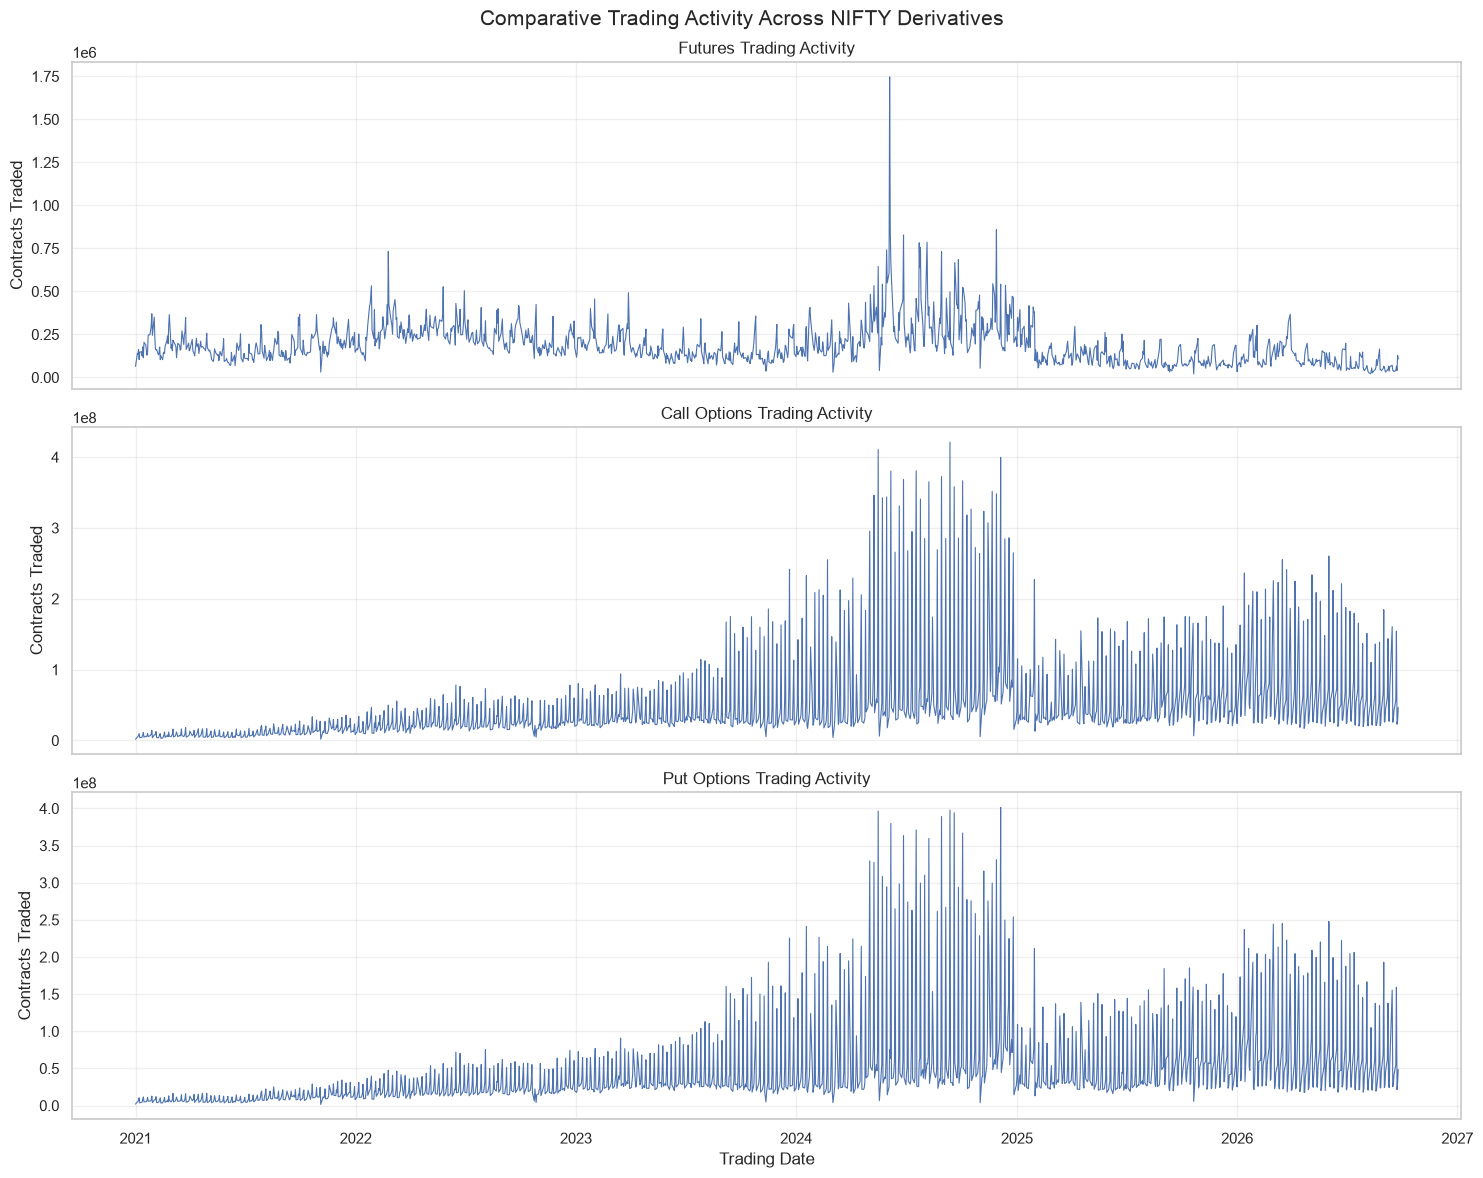

In [60]:
fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)

volume_columns = [
    ("Futures_Contracts", "Futures Trading Activity"),
    ("CE_Contracts", "Call Options Trading Activity"),
    ("PE_Contracts", "Put Options Trading Activity")
]

for ax, (column, title) in zip(axes, volume_columns):

    ax.plot(
        daily_comparison["Date"],
        daily_comparison[column],
        linewidth=0.8
    )

    ax.set_title(title)
    ax.set_ylabel("Contracts Traded")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Trading Date")

plt.suptitle(
    "Comparative Trading Activity Across NIFTY Derivatives",
    fontsize=15
)

plt.tight_layout()
plt.show()

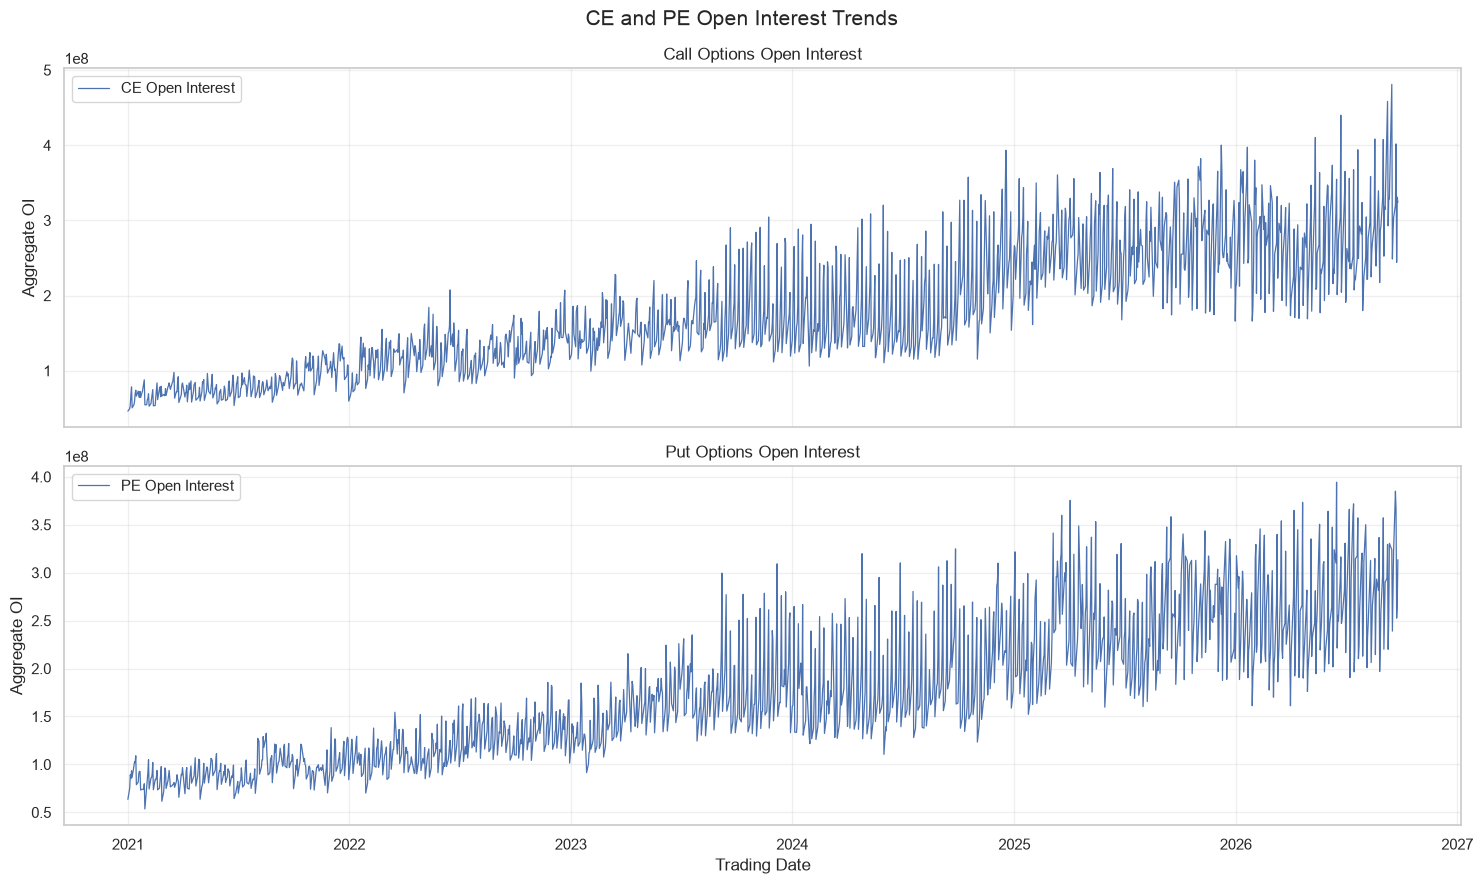

In [61]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

axes[0].plot(
    oi_comparison["Date"],
    oi_comparison["CE_OI"],
    label="CE Open Interest",
    linewidth=0.9
)

axes[0].set_title("Call Options Open Interest")
axes[0].set_ylabel("Aggregate OI")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(
    oi_comparison["Date"],
    oi_comparison["PE_OI"],
    label="PE Open Interest",
    linewidth=0.9
)

axes[1].set_title("Put Options Open Interest")
axes[1].set_xlabel("Trading Date")
axes[1].set_ylabel("Aggregate OI")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.suptitle("CE and PE Open Interest Trends", fontsize=15)
plt.tight_layout()
plt.show()

In [62]:
final_comparison_metrics = pd.DataFrame({
    "Metric": [
        "Futures Daily Return Volatility (%)",
        "CE Daily Aggregate Return Volatility (%)",
        "PE Daily Aggregate Return Volatility (%)",
        "Average Daily PCR",
        "Median Daily PCR",
        "CE-PE Return Correlation",
        "CE-PE Open Interest Correlation"
    ],
    "Value": [
        daily_returns["Futures_Return"].std(),
        daily_returns["CE_Return"].std(),
        daily_returns["PE_Return"].std(),
        pcr_daily["PCR"].mean(),
        pcr_daily["PCR"].median(),
        daily_returns["CE_Return"].corr(
            daily_returns["PE_Return"]
        ),
        oi_comparison["CE_OI"].corr(
            oi_comparison["PE_OI"]
        )
    ]
})

display(final_comparison_metrics.round(4))

,Metric,Value
0,Futures Daily Return Volatility (%),0.8939
1,CE Daily Aggregate Return Volatility (%),3.3052
2,PE Daily Aggregate Return Volatility (%),5.2670
3,Average Daily PCR,1.0278
4,Median Daily PCR,1.0013
5,CE-PE Return Correlation,-0.8015
6,CE-PE Open Interest Correlation,0.8802


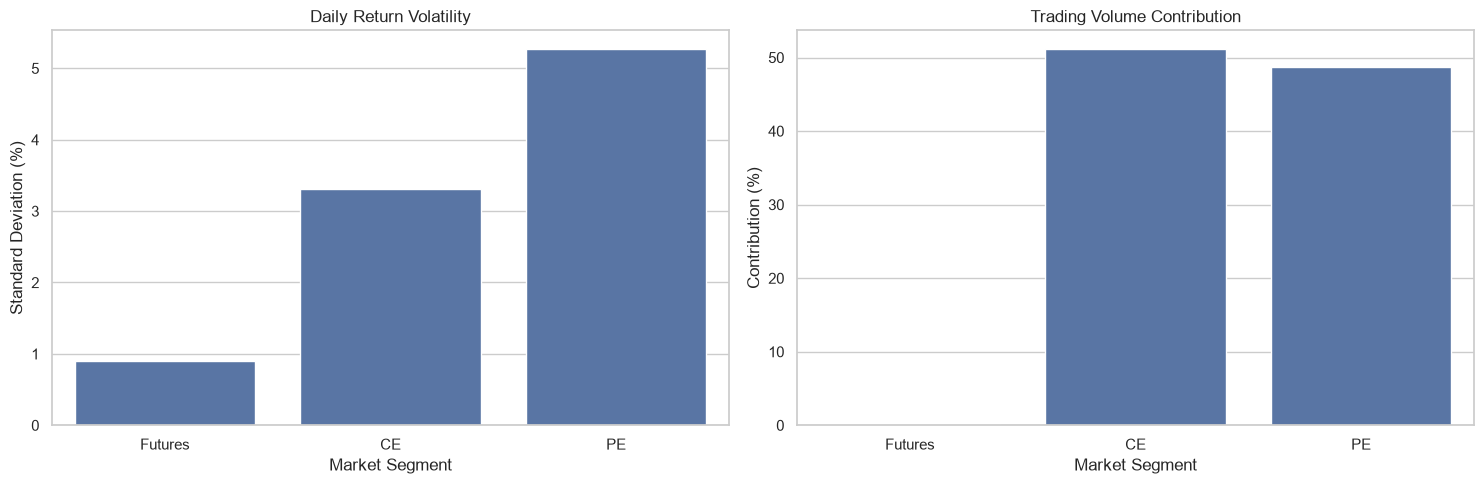

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Daily return volatility
sns.barplot(
    data=volatility_comparison,
    x="Market Segment",
    y="Daily Volatility (%)",
    ax=axes[0]
)

axes[0].set_title("Daily Return Volatility")
axes[0].set_ylabel("Standard Deviation (%)")

# Trading volume contribution
sns.barplot(
    data=volume_contribution,
    x="Market Segment",
    y="Contribution (%)",
    ax=axes[1]
)

axes[1].set_title("Trading Volume Contribution")
axes[1].set_ylabel("Contribution (%)")

plt.tight_layout()
plt.show()

### Section 9 - Key Findings

The comparative analysis produced findings across trading activity,
price behaviour, Open Interest, PCR, and statistical relationships.

The actual numerical results from the preceding tables and
visualizations should be used to identify:

1. The market segment with the highest trading activity.
2. Differences in daily aggregate return variability.
3. The relationship between CE and PE Open Interest.
4. Changes in the Put-Call Ratio during the study period.
5. Relationships between futures, CE, and PE returns.
6. Results of the statistical hypothesis tests.

The findings are descriptive and should be interpreted in
the context of the limitations of aggregate option data.

## 10. Final Conclusions

This notebook presented a comparative and statistical analysis
of NIFTY 50 Futures, Call Options (CE), and Put Options (PE).

The analysis extended the exploratory work performed in
Notebook 3 by examining:

- Comparative trading activity.
- Daily average prices and returns.
- CE and PE Open Interest.
- Put-Call Ratio.
- Correlation between market variables.
- Statistical differences and relationships.

The results provide a broader understanding of the behaviour
of the NIFTY 50 derivatives market over the study period.

In [64]:
final_project_summary = pd.DataFrame({
    "Dataset": [
        "Futures",
        "Call Options (CE)",
        "Put Options (PE)"
    ],
    "Total Records": [
        len(futures_df),
        len(calls_df),
        len(puts_df)
    ],
    "Total Contracts Traded": [
        futures_df["No. of contracts"].sum(),
        calls_df["No. of contracts"].sum(),
        puts_df["No. of contracts"].sum()
    ],
    "Average Closing Price": [
        futures_df["Close"].mean(),
        calls_df["Close"].mean(),
        puts_df["Close"].mean()
    ],
    "Average Open Interest": [
        futures_df["Open Int"].mean(),
        calls_df["Open Int"].mean(),
        puts_df["Open Int"].mean()
    ]
})

display(final_project_summary.round(3))

,Dataset,Total Records,Total Contracts Traded,Average Closing Price,Average Open Interest
0,Futures,4294,"268,778,637.0000","20,735.3820","4,978,355.1160"
1,Call Options (CE),1261810,"73,404,424,377.0000","1,341.4150","362,453.8500"
2,Put Options (PE),1300689,"69,913,372,822.0000",810.5930,"326,762.3750"


In [65]:
final_statistical_summary = pd.DataFrame({
    "Metric": [
        "Common Trading Days",
        "Average PCR",
        "Median PCR",
        "CE-PE Return Correlation",
        "CE-PE Open Interest Correlation",
        "Futures Return Volatility (%)",
        "CE Return Volatility (%)",
        "PE Return Volatility (%)"
    ],
    "Value": [
        len(common_dates),
        pcr_daily["PCR"].mean(),
        pcr_daily["PCR"].median(),
        daily_returns["CE_Return"].corr(
            daily_returns["PE_Return"]
        ),
        oi_comparison["CE_OI"].corr(
            oi_comparison["PE_OI"]
        ),
        daily_returns["Futures_Return"].std(),
        daily_returns["CE_Return"].std(),
        daily_returns["PE_Return"].std()
    ]
})

display(final_statistical_summary.round(4))

,Metric,Value
0,Common Trading Days,"1,421.0000"
1,Average PCR,1.0278
2,Median PCR,1.0013
3,CE-PE Return Correlation,-0.8015
4,CE-PE Open Interest Correlation,0.8802
5,Futures Return Volatility (%),0.8939
6,CE Return Volatility (%),3.3052
7,PE Return Volatility (%),5.2670


### Overall Conclusion

This project performed an exploratory, comparative, and statistical
analysis of NIFTY 50 Futures, Call Options, and Put Options data.

The study covered the period from 1 January 2021 to
25 September 2026 using historical NSE derivatives data.

The analysis began with understanding the structure and quality
of the raw datasets. Data preprocessing involved standardizing
columns, converting data types, handling missing values,
identifying exact duplicates, validating records, and exporting
the processed datasets.

The exploratory analysis investigated trading activity,
futures price movements, option premiums, strike prices,
expiry dates, Open Interest, and return distributions.

The comparative analysis extended this work through daily
market activity comparisons, CE and PE Open Interest analysis,
Put-Call Ratio calculations, correlation analysis, and
statistical hypothesis testing.

The project demonstrates how data analysis and statistical
techniques can be applied to historical derivatives market
data to identify patterns, relationships, and differences
between market segments.

### Limitations

1. Option premium averages combine different strike prices
   and expiry dates and do not represent individual contract
   returns.

2. Aggregate Open Interest combines observations across
   available strikes and expiries.

3. Correlation does not establish causation.

4. Statistical tests may be affected by time-series
   dependence and non-normality.

5. September 2026 is a partial month because the dataset
   ends on 25 September 2026.

### Future Scope

Further research could include:

- Contract-level options analysis.
- Implied volatility analysis.
- Option Greeks analysis.
- Expiry-specific market behaviour.
- Predictive modelling of market volatility.
- Machine learning applications to derivatives data.

The project provides a foundation for further quantitative
research into the NIFTY 50 derivatives market.

In [66]:
required_objects = [
    "daily_comparison",
    "daily_prices",
    "daily_returns",
    "monthly_comparison",
    "yearly_comparison",
    "oi_comparison",
    "pcr_daily",
    "pearson_correlation",
    "spearman_correlation",
    "hypothesis_test_summary",
    "final_project_summary",
    "final_statistical_summary"
]

final_verification = pd.DataFrame({
    "Analysis Object": required_objects,
    "Available": [
        name in globals()
        for name in required_objects
    ]
})

display(final_verification)

print("\nNotebook 4 Verification")
print("-----------------------")
print("All objects available:", final_verification["Available"].all())
print("Common trading days:", len(common_dates))
print("Futures records:", len(futures_df))
print("CE records:", len(calls_df))
print("PE records:", len(puts_df))

assert final_verification["Available"].all(), (
    "Some analysis objects are missing. Run the notebook from the beginning."
)

print("\nNotebook 4 analysis objects verified.")

,Analysis Object,Available
0,daily_comparison,True
1,daily_prices,True
2,daily_returns,True
3,monthly_comparison,True
4,yearly_comparison,True
5,oi_comparison,True
6,pcr_daily,True
7,pearson_correlation,True
8,spearman_correlation,True
9,hypothesis_test_summary,True



Notebook 4 Verification
-----------------------
All objects available: True
Common trading days: 1421
Futures records: 4294
CE records: 1261810
PE records: 1300689

Notebook 4 analysis objects verified.
